# Laboratory 4: Unsupervised Machine Learning — Comprehensive Clustering Analysis
## Comparative Evaluation of Partition-Based (K-Means), Hierarchical (Agglomerative), Density-Based (DBSCAN), and Soft (Fuzzy C-Means) Clustering Paradigms

---

### Executive Overview & Laboratory Roadmap
Unsupervised cluster analysis seeks to discover intrinsic structure, geometric manifolds, and natural groupings in unlabelled high-dimensional data without ground-truth supervisory signals. In this laboratory, we explore four major clustering paradigms, implementing each algorithm from scratch, tuning its hyperparameters, validating against Scikit-Learn reference implementations, and profiling discovered clusters:

1. **Part 1: K-Means Clustering (Hard Partitioning)**: Lloyd's algorithm from scratch applied to architectural and physical attributes of the **Ames Housing dataset**. Evaluation via Elbow (WCSS / Inertia) analysis and Silhouette maximization.
2. **Part 2: Hierarchical Clustering (Agglomerative Hierarchy & Dendrogram Topology)**: Complete agglomerative hierarchy from scratch, investigating Single, Complete, Average, and Ward linkage criteria, Cophenetic Correlation Coefficients ($CPCC$), and truncated dendrograms on **Spotify Audio Features**.
3. **Part 3: Density-Based Spatial Clustering of Applications with Noise (DBSCAN)**: Custom density-connected manifold clustering with automated $\varepsilon$ discovery via the $k$-distance graph, robust core/border/noise segregation, and outlier isolation on acoustic features.
4. **Part 4: Fuzzy C-Means Clustering (Soft Fuzzy Partitioning)**: Alternating Least Squares (ALS) optimization with soft membership matrices ($u_{ij}$), tuning cluster granularity via the Fuzzy Partition Coefficient ($FPC$), and identifying pure archetypes versus crossover hybrid tracks.
5. **Part 5: Unified Cross-Paradigm Benchmark & Comprehensive Synthesis**: Comparative assessment across mathematical assumptions, time/space complexities, geometry constraints, and production selection criteria.


---

# Part 1: K-Means Clustering (Hard Partitioning)

### 1. Theoretical Foundation & Mathematical Formulations

K-Means is a centroid-based iterative partitioning algorithm that divides a dataset $X = \{x_1, x_2, \dots, x_N\} \subset \mathbb{R}^d$ into $K$ disjoint, non-empty clusters $S = \{S_1, S_2, \dots, S_K\}$.

#### Mathematical Objective (Inertia / WCSS):
The algorithm minimizes the Within-Cluster Sum of Squares (WCSS), also known as **inertia**:
$$J = \sum_{k=1}^{K} \sum_{x_i \in S_k} \| x_i - \mu_k \|^2$$
where $\mu_k = \frac{1}{|S_k|} \sum_{x_i \in S_k} x_i$ represents the arithmetic centroid of cluster $S_k$.

#### Algorithmic Mechanism (Lloyd's Iterative Relaxation):
1. **Centroid Initialization**: Select $K$ initial cluster centroids $\mu_1^{(0)}, \dots, \mu_K^{(0)}$ uniformly at random from the dataset (or via $k$-means++ seeding).
2. **Assignment Step (Voronoi Partitioning)**: Assign each sample $x_i$ to its nearest centroid under Euclidean distance:
   $$c_i^{(t)} = \arg\min_{k \in \{1, \dots, K\}} \| x_i - \mu_k^{(t)} \|^2$$
3. **Centroid Update Step**: Recompute each cluster centroid as the center of mass of its assigned points:
   $$\mu_k^{(t+1)} = \frac{1}{|S_k^{(t)}|} \sum_{x_i \in S_k^{(t)}} x_i$$
4. **Convergence Criterion**: Repeat steps 2 and 3 until centroid displacement falls below a tolerance threshold ($\max_k \|\mu_k^{(t+1)} - \mu_k^{(t)}\| < \varepsilon$) or maximum iterations are exhausted.

---

### 2. Dataset Ingestion, Exploratory Data Analysis & Preprocessing (Ames Housing)
We evaluate K-Means on the **Ames Housing dataset** (`../datasets/ames.csv`), focusing on primary physical, spatial, and structural home dimensions.


In [72]:
import numpy as np
import pandas as pd

file_path = "../datasets/ames.csv"
csv = pd.read_csv(file_path)

dataframe = pd.DataFrame(csv)
dataframe.head()

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YearSold,SaleType,SaleCondition,SalePrice
0,One_Story_1946_and_Newer_All_Styles,Residential_Low_Density,141.0,31770.0,Pave,No_Alley_Access,Slightly_Irregular,Lvl,AllPub,Corner,...,0.0,No_Pool,No_Fence,NaN,0.0,5,2010,WD,Normal,215000
1,One_Story_1946_and_Newer_All_Styles,Residential_High_Density,80.0,11622.0,Pave,No_Alley_Access,Regular,Lvl,AllPub,Inside,...,0.0,No_Pool,Minimum_Privacy,NaN,0.0,6,2010,WD,Normal,105000
2,One_Story_1946_and_Newer_All_Styles,Residential_Low_Density,81.0,14267.0,Pave,No_Alley_Access,Slightly_Irregular,Lvl,AllPub,Corner,...,0.0,No_Pool,No_Fence,Gar2,12500.0,6,2010,WD,Normal,172000
3,One_Story_1946_and_Newer_All_Styles,Residential_Low_Density,93.0,11160.0,Pave,No_Alley_Access,Regular,Lvl,AllPub,Corner,...,0.0,No_Pool,No_Fence,NaN,0.0,4,2010,WD,Normal,244000
4,Two_Story_1946_and_Newer,Residential_Low_Density,74.0,13830.0,Pave,No_Alley_Access,Slightly_Irregular,Lvl,AllPub,Inside,...,0.0,No_Pool,Minimum_Privacy,NaN,0.0,3,2010,WD,Normal,189900


In [73]:
features = [
    'GrLivArea', 'TotalBsmtSF', 'LotArea', 'YearBuilt', 'OverallQual', 'FullBath', 'BedroomAbvGr'
]

df = dataframe[features].copy()

df.head()

,GrLivArea,TotalBsmtSF,LotArea,YearBuilt,OverallQual,FullBath,BedroomAbvGr
0,1656.0,1080.0,31770.0,1960,Above_Average,1,3
1,896.0,882.0,11622.0,1961,Average,1,2
2,1329.0,1329.0,14267.0,1958,Above_Average,1,3
3,2110.0,2110.0,11160.0,1968,Good,2,3
4,1629.0,928.0,13830.0,1997,Average,2,3


In [74]:
# Check for null values

df.isnull().sum()

GrLivArea       0
TotalBsmtSF     0
LotArea         0
YearBuilt       0
OverallQual     0
FullBath        0
BedroomAbvGr    0
dtype: int64

In [75]:
# Check the distribution

df.skew(numeric_only=True)

GrLivArea        1.274110
TotalBsmtSF      1.150846
LotArea         12.820898
YearBuilt       -0.604462
FullBath         0.171952
BedroomAbvGr     0.305694
dtype: float64

In [76]:
# Applying Log transform for all features having |skew| > 1.5
# In this case it is 'LotArea'
df_new = df.copy()
df_new['LotArea'] = np.log1p(df_new['LotArea'])
df_new.skew(numeric_only=True)

GrLivArea       1.274110
TotalBsmtSF     1.150846
LotArea        -0.498335
YearBuilt      -0.604462
FullBath        0.171952
BedroomAbvGr    0.305694
dtype: float64

In [77]:
df_new.head()

,GrLivArea,TotalBsmtSF,LotArea,YearBuilt,OverallQual,FullBath,BedroomAbvGr
0,1656.0,1080.0,10.366309,1960,Above_Average,1,3
1,896.0,882.0,9.360741,1961,Average,1,2
2,1329.0,1329.0,9.565775,1958,Above_Average,1,3
3,2110.0,2110.0,9.320181,1968,Good,2,3
4,1629.0,928.0,9.534668,1997,Average,2,3


In [78]:
df_new_encoded = pd.get_dummies(df_new, drop_first=True)
df_new_encoded.head()

,GrLivArea,TotalBsmtSF,LotArea,YearBuilt,FullBath,BedroomAbvGr,OverallQual_Average,OverallQual_Below_Average,OverallQual_Excellent,OverallQual_Fair,OverallQual_Good,OverallQual_Poor,OverallQual_Very_Excellent,OverallQual_Very_Good,OverallQual_Very_Poor
0,1656.0,1080.0,10.366309,1960,1,3,False,False,False,False,False,False,False,False,False
1,896.0,882.0,9.360741,1961,1,2,True,False,False,False,False,False,False,False,False
2,1329.0,1329.0,9.565775,1958,1,3,False,False,False,False,False,False,False,False,False
3,2110.0,2110.0,9.320181,1968,2,3,False,False,False,False,True,False,False,False,False
4,1629.0,928.0,9.534668,1997,2,3,True,False,False,False,False,False,False,False,False


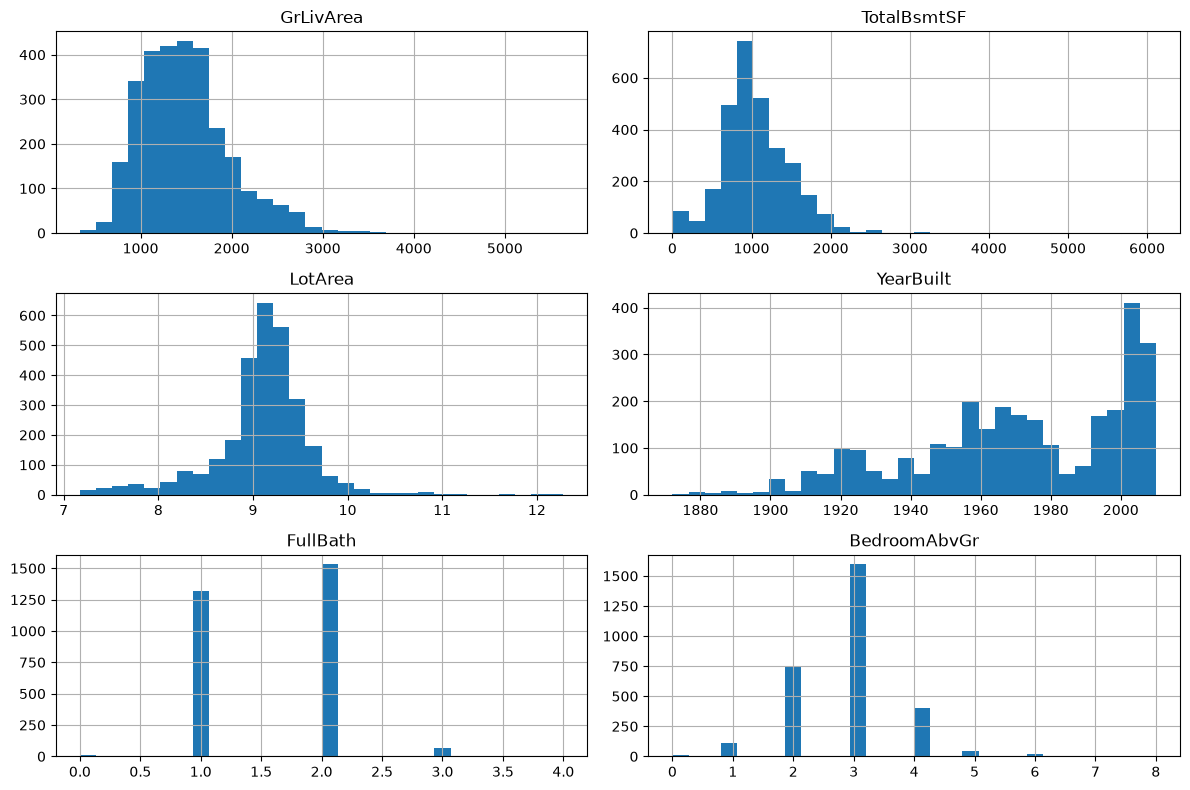

In [79]:
# Checking the data visually for patters

import matplotlib.pyplot as plt
import seaborn as sns

df_new_encoded.hist(bins=30, figsize=(12, 8))
plt.tight_layout()
plt.show()

---

### 3. Feature Standardization
Because Euclidean distance is isotropic and unweighted, attributes with larger numeric scales (e.g., `GrLivArea`, `LotArea`) would disproportionately dominate centroid updates over bounded ordinal variables (e.g., `FullBath`, `BedroomAbvGr`). We apply standard Z-score normalization:
$$z = \frac{x - \mu}{\sigma}$$


In [80]:
# Preprocess the data

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
x_scaled = scaler.fit_transform(df_new_encoded)

---

### 4. Custom From-Scratch K-Means Implementation (`class KMeans`)
We implement a vectorized `KMeans` class featuring random centroid seeding, vectorized Euclidean distance computation, tolerance-based early stopping, and automatic inertia computation.


In [ ]:
class KMeans:
    def __init__(self, k: int = 3, max_iter: int = 300, tolerance: float = 1e-4, random_state: int = 42):
        self.k: int = k
        self.max_iter: int = max_iter
        self.tolerance: float = tolerance
        self.random_state: int = random_state
        self.centroids: np.ndarray = None
        self.labels: np.ndarray = None
        self._inertia = None

    def optimize_centroids(self, X: np.ndarray, n_samples: int):
        for iteration in range(self.max_iter):
            distances: np.ndarray = np.linalg.norm(X[:, np.newaxis, :] - self.centroids[np.newaxis, :, :], axis=2)
            self.labels: np.ndarray = np.argmin(distances, axis=1)

            new_centroids = np.zeros_like(self.centroids)
            for j in range(self.k):
                cluster_points: np.ndarray = X[self.labels == j]
                if len(cluster_points) > 0:
                    new_centroids[j] = cluster_points.mean(axis=0)
                else:
                    new_centroids[j] = X[np.random.choice(n_samples)]

            shift = np.linalg.norm(new_centroids - self.centroids)
            self.centroids = new_centroids

            if shift < self.tolerance:
                break

    def final_inertia(self, X: np.ndarray):
        self._inertia = np.sum((X - self.centroids[self.labels]) ** 2)

    def fit(self, X: np.ndarray):
        np.random.seed(self.random_state)
        n_samples, n_features = X.shape

        initial_indices = np.random.choice(n_samples, size=self.k, replace=False)
        self.centroids = X[initial_indices].copy()

        self.optimize_centroids(X=X, n_samples=n_samples)
        self.final_inertia(X=X)

        return self

    def predict(self, X: np.ndarray):
        distances = np.linalg.norm(X[:, np.newaxis, :] - self.centroids[np.newaxis, :, :], axis=2)
        return np.argmin(distances, axis=1)

    def fit_predict(self, X: np.ndarray):
        self.fit(X)
        return self.labels

---

### 5. Hyperparameter Tuning: Determining Optimal $K$ via Elbow Method & Silhouette Analysis
To determine the natural number of residential market clusters, we evaluate $K \in [2, 15]$ across two complementary metrics:
1. **Inertia / WCSS (Elbow Method)**: Identifying the inflection point beyond which adding clusters yields diminishing reductions in variance.
2. **Silhouette Coefficient**: Quantifying cluster cohesion versus separation:
   $$s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}$$
   where $a(i)$ is the mean intra-cluster distance and $b(i)$ is the nearest-cluster mean distance.


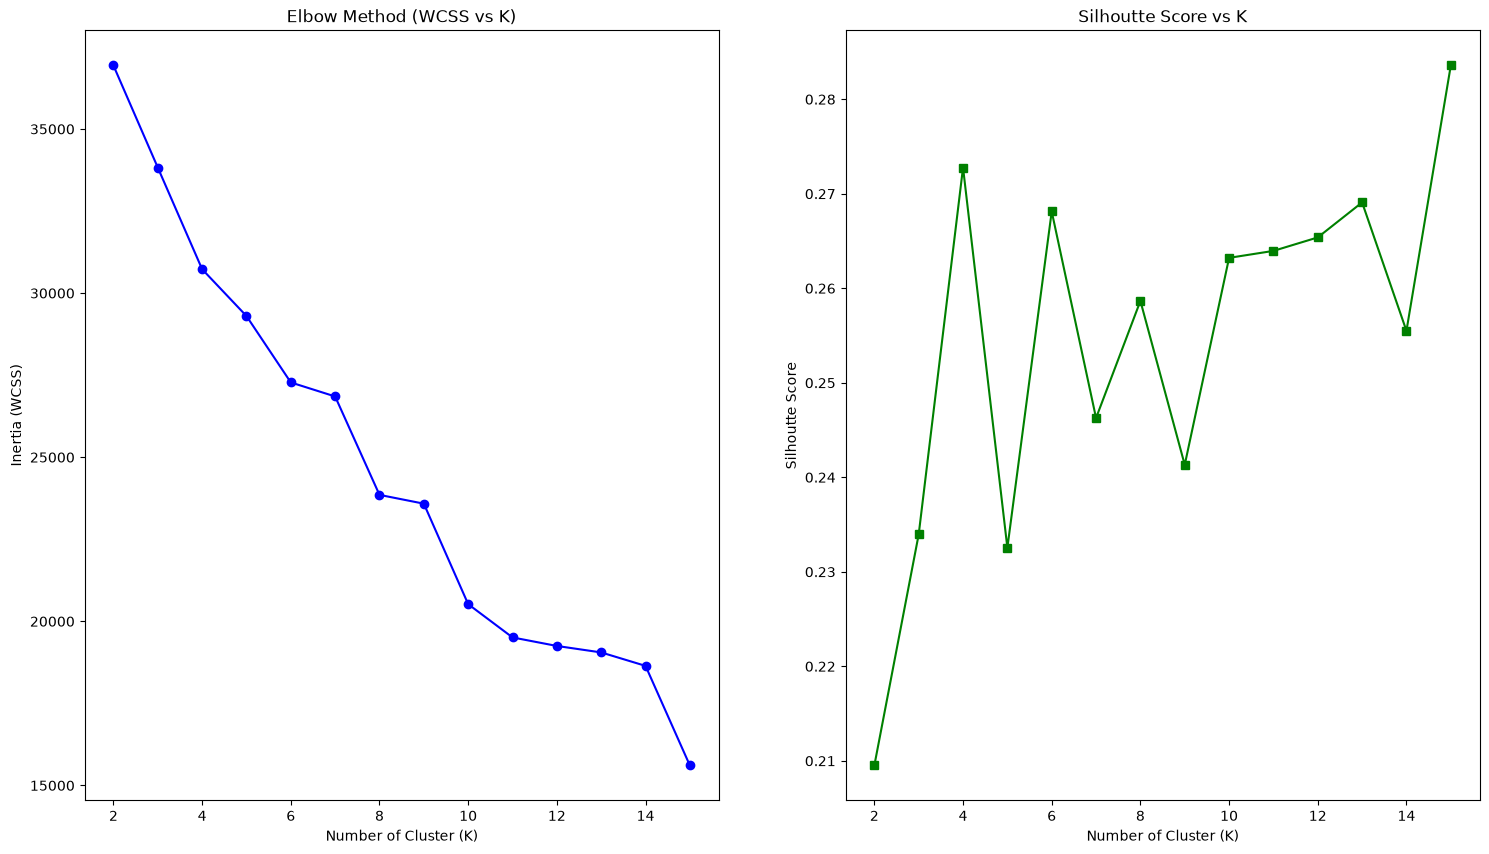

In [82]:
# Determining Optimal k

from sklearn.metrics import silhouette_score

k_range = range(2, 16) # 2 - 10
wcss_list = []
silhouette_list = []

for k in k_range:
    model = KMeans(k=k)
    model.fit(X=x_scaled)
    wcss_list.append(model._inertia)

    score = silhouette_score(x_scaled, model.labels)
    silhouette_list.append(score)

fig, ax = plt.subplots(1, 2, figsize=(18, 10))

ax[0].plot(k_range, wcss_list, marker="o", color="blue")
ax[0].set_title("Elbow Method (WCSS vs K)")
ax[0].set_xlabel("Number of Cluster (K)")
ax[0].set_ylabel("Inertia (WCSS)")

ax[1].plot(k_range, silhouette_list, marker="s", color="green")
ax[1].set_title("Silhoutte Score vs K")
ax[1].set_xlabel("Number of Cluster (K)")
ax[1].set_ylabel("Silhoutte Score")

plt.show()

---

### 6. Model Fitting ($K=2$) & Residential Cluster Profiling
Based on the prominent peak in silhouette score, we fit our final model with **$K=2$** and analyze the profile of the two discovered housing segments against sale price.


In [83]:
optimal_k = 2
km = KMeans(k=optimal_k)
km.fit(X=x_scaled)
print(f"Cluster Sizes : {np.bincount(km.labels)}")
print(f"Inertia : {km._inertia}")
km_score = silhouette_score(x_scaled, km.labels)

Cluster Sizes : [1435 1495]
Inertia : 36935.24112598502


In [84]:
# Analysis

df_profile = df.copy()
df_profile['Cluster'] = km.labels
df_profile['SalePrice'] = dataframe['SalePrice']
df_profile = df_profile.drop(columns=['OverallQual'])
# print(df_profile.head())
profile_summary = df_profile.groupby('Cluster').mean().round(1)
profile_summary

,GrLivArea,TotalBsmtSF,LotArea,YearBuilt,FullBath,BedroomAbvGr,SalePrice
Cluster,,,,,,,
0,1808.3,1263.8,11406.5,1991.2,2.0,3.0,234018.2
1,1203.5,847.2,8939.8,1952.3,1.1,2.7,129710.0


---

### 7. Validation Against Scikit-Learn Reference Implementation
We benchmark our from-scratch `KMeans` against `sklearn.cluster.KMeans` using the **Adjusted Rand Index (ARI)** to quantify agreement between cluster assignments.


In [85]:
# Validating against Sklearn's KMeans

from sklearn.cluster import KMeans as SkLearnMeans
from sklearn.metrics import adjusted_rand_score

sklearn_km = SkLearnMeans(n_clusters=optimal_k, random_state=42, n_init=10)
sklearn_km.fit(x_scaled)

sklearn_inertia = sklearn_km.inertia_
sklearn_silhoutte = silhouette_score(x_scaled, sklearn_km.labels_)

ari_score = adjusted_rand_score(km.labels, sklearn_km.labels_)

comparison_df = pd.DataFrame({
    'Metric': [
        'Inertia (WCSS)',
        'Silhouette Score',
        'Cluster Sizes',
        'Adjusted Rand Index (ARI)'
    ],
    'Custom KMeans': [
        f"{km._inertia:.2f}",
        f"{km_score:.4f}",
        f"{np.bincount(km.labels).tolist()}",
        "1.0000 (Self)"
    ],
    'Sklearn KMeans': [
        f"{sklearn_inertia:.2f}",
        f"{sklearn_silhoutte:.4f}",
        f"{np.bincount(sklearn_km.labels_).tolist()}",
        f"{ari_score:.4f}"
    ]
})

comparison_df

,Metric,Custom KMeans,Sklearn KMeans
0,Inertia (WCSS),36935.24,36935.24
1,Silhouette Score,0.2095,0.2095
2,Cluster Sizes,"[1435, 1495]","[1495, 1435]"
3,Adjusted Rand Index (ARI),1.0000 (Self),1.0000


---

### 8. 2D PCA Dimensionality Reduction & Cluster Visualization
To verify geometric cluster separation in 2D Euclidean space, we project the standardized high-dimensional residential feature space onto its first two Principal Components ($PC_1$ and $PC_2$).


PC1 explains 21.62% variance
PC2 explains 10.35% variance
Total 2D Variance Captured: 31.97%


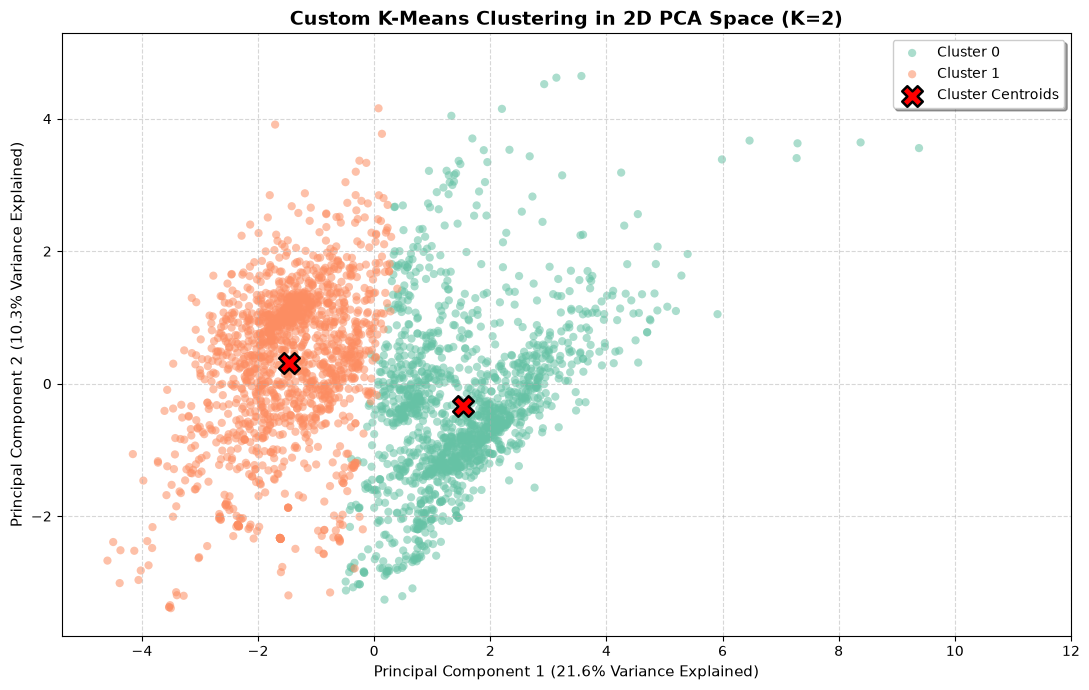

In [86]:
# ==========================================================
# 2. PCA Dimensionality Reduction & Cluster Visualization
# ==========================================================
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Fit PCA on the 15-dimensional standardized feature space
pca = PCA(n_components=2, random_state=42)
x_pca = pca.fit_transform(x_scaled)

# 2. IMPORTANT: Project the fitted 15D centroids into the same 2D PCA coordinate space!
centroids_pca = pca.transform(km.centroids)

var_pc1 = pca.explained_variance_ratio_[0] * 100
var_pc2 = pca.explained_variance_ratio_[1] * 100
total_var = var_pc1 + var_pc2

print(f"PC1 explains {var_pc1:.2f}% variance")
print(f"PC2 explains {var_pc2:.2f}% variance")
print(f"Total 2D Variance Captured: {total_var:.2f}%")

# 3. Plot the PCA Scatter
plt.figure(figsize=(11, 7), dpi=100)
palette = sns.color_palette("Set2", n_colors=km.k)

# Scatter plot each cluster
for cluster_id in range(km.k):
    cluster_mask = (km.labels == cluster_id)
    plt.scatter(
        x_pca[cluster_mask, 0],
        x_pca[cluster_mask, 1],
        label=f"Cluster {cluster_id}",
        color=palette[cluster_id],
        alpha=0.55,
        s=35,
        edgecolor='none'
    )

# 4. Plot the Cluster Centroids as prominent markers
plt.scatter(
    centroids_pca[:, 0],
    centroids_pca[:, 1],
    c='red',
    marker='X',
    s=220,
    edgecolor='black',
    linewidth=1.8,
    label='Cluster Centroids'
)

plt.title(f"Custom K-Means Clustering in 2D PCA Space (K={km.k})", fontsize=14, fontweight='bold')
plt.xlabel(f"Principal Component 1 ({var_pc1:.1f}% Variance Explained)", fontsize=11)
plt.ylabel(f"Principal Component 2 ({var_pc2:.1f}% Variance Explained)", fontsize=11)
plt.legend(loc='upper right', frameon=True, shadow=True)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


# Part 2: Hierarchical Clustering (Agglomerative & Divisive)
## Dendrogram Topology, Linkage Mechanics & Audio Manifold Segmentation

---

### 1. Theoretical Foundation & Mathematical Formulations

**Hierarchical Clustering** is a family of clustering algorithms that constructs a nested hierarchy of clusters represented visually as a binary tree called a **dendrogram**. 

Unlike partitioning methods ($K$-Means, Fuzzy C-Means) that require pre-specifying $K$, hierarchical clustering produces a multi-scale clustering resolution simultaneously, allowing analysts to choose the optimal number of clusters post-hoc by cutting the dendrogram at any desired height.

---

### Two Fundamental Paradigms:
1. **Agglomerative (Bottom-Up)**:
   - Begins with each data point in its own singleton cluster ($N$ clusters for $N$ samples).
   - At each successive iteration, the two most similar (nearest) clusters are merged according to a specified **linkage criterion**.
   - Process repeats $N-1$ times until all points belong to a single root cluster.
2. **Divisive (Top-Down)**:
   - Begins with all data points in a single mega-cluster.
   - Recursively splits clusters until all samples are singletons (computationally intensive, requiring $2^{N-1}-1$ possible binary splits at the root).

---

### Mathematical Linkage Formulations

Let $A$ and $B$ be two disjoint clusters, and let $d(a, b) = \|a - b\|_2$ denote the Euclidean distance between sample vectors $a \in A$ and $b \in B$:

#### 1. Single Linkage (Nearest Neighbor / Minimum Distance)
$$d_{\text{single}}(A, B) = \min_{a \in A, \, b \in B} d(a, b)$$
* **Topological Behavior**: Capable of tracing non-elliptical manifolds, but notoriously vulnerable to the **chaining effect**, where noisy bridges cause disparate clusters to merge prematurely.

#### 2. Complete Linkage (Furthest Neighbor / Maximum Distance)
$$d_{\text{complete}}(A, B) = \max_{a \in A, \, b \in B} d(a, b)$$
* **Topological Behavior**: Enforces compact, spherical, and roughly equal-diameter clusters. Highly robust against chaining, but sensitive to outliers.

#### 3. Average Linkage (UPGMA - Unweighted Pair Group Method with Arithmetic Mean)
$$d_{\text{average}}(A, B) = \frac{1}{|A| \cdot |B|} \sum_{a \in A} \sum_{b \in B} d(a, b)$$
* **Topological Behavior**: Computes the mean pairwise distance between all sample pairs across both clusters. Compromises between the extremes of single and complete linkage.

#### 4. Ward's Minimum Variance Linkage
Instead of measuring inter-point distances directly, Ward's method minimizes the increase in total within-cluster **Error Sum of Squares (ESS)** upon merging clusters $A$ and $B$:
$$\Delta \text{ESS}(A, B) = \text{ESS}_{A \cup B} - (\text{ESS}_A + \text{ESS}_B) = \frac{|A| \cdot |B|}{|A| + |B|} \|\mu_A - \mu_B\|_2^2$$
where $\mu_A$ and $\mu_B$ are the centroid mean vectors of clusters $A$ and $B$.
* **Topological Behavior**: Produces highly balanced, spherical clusters with minimum internal variance. It is mathematically the hierarchical analogue of $K$-Means.

---

### Cophenetic Correlation Coefficient ($CPCC$)
To quantitatively measure how faithfully a dendrogram preserves the original pairwise distances in the feature space:
$$CPCC = \frac{\sum_{i < j} (D_{ij} - \bar{D})(C_{ij} - \bar{C})}{\sqrt{\sum_{i < j} (D_{ij} - \bar{D})^2 \sum_{i < j} (C_{ij} - \bar{C})^2}}$$
where $D_{ij}$ is the Euclidean distance between points $i$ and $j$, and $C_{ij}$ is the **cophenetic distance** (the height in the dendrogram where $i$ and $j$ first merge into the same cluster). A $CPCC$ close to $1.0$ indicates superior metric preservation.


---

## 2. Dataset Ingestion, Feature Selection & Standardization

To ensure comprehensive cross-algorithm benchmarking across all of Lab 4, we evaluate Hierarchical Clustering on the **Spotify Audio Features dataset** (`../datasets/spotify.csv`).

### Evaluated Continuous Attributes:
* `danceability`, `energy`, `loudness`, `speechiness`, `acousticness`, `valence`, `tempo`.

### Sampling Strategy
Agglomerative clustering on $N$ points requires computing an $N \times N$ distance matrix and performing $N-1$ merge operations ($O(N^2)$ space, $O(N^2 \log N)$ to $O(N^3)$ time). We sample **$3,000$ tracks** for rigorous quantitative evaluation and extract a curated **$20$-track sample with song titles** to render an interpretable, un-truncated pedagogical dendrogram.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

# Set aesthetic styling
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.sans-serif': 'DejaVu Sans', 'font.size': 11})

# Ingest Spotify Dataset
file_path = "../datasets/spotify.csv"
dataframe = pd.read_csv(file_path)
print(f"Dataset Ingested: {dataframe.shape[0]:,} tracks across {dataframe.shape[1]} attributes.")

# Select continuous acoustic features
features = [
    'danceability', 'energy', 'loudness', 'speechiness',
    'acousticness', 'valence', 'tempo'
]

# Clean nulls and remove duplicate track_ids
df_clean = dataframe.dropna(subset=features).drop_duplicates(subset=['track_id']).copy()

# Sample 3,000 tracks with fixed seed
sample_df = df_clean.sample(n=3000, random_state=42).reset_index(drop=True)

# Standardize features (mean=0, variance=1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(sample_df[features])

# Curated 20-track subset for pedagogical dendrogram inspection
toy_sample = sample_df.sample(n=20, random_state=101).reset_index(drop=True)
X_toy_scaled = scaler.transform(toy_sample[features])
toy_labels = [f"{row['track_name'][:18]} ({row['track_artist'][:12]})" for _, row in toy_sample.iterrows()]

print(f"Standardized Sample Matrix Shape: {X_scaled.shape}")
print(f"Curated 20-Track Subset Extracted for Full Dendrogram Tracing.")
toy_sample[['track_name', 'track_artist', 'playlist_genre'] + features].head()

Dataset Ingested: 32,833 tracks across 23 attributes.
Standardized Sample Matrix Shape: (3000, 7)
Curated 20-Track Subset Extracted for Full Dendrogram Tracing.


,track_name,track_artist,playlist_genre,danceability,energy,loudness,speechiness,acousticness,valence,tempo
0,Lost,T-Dre,latin,0.762,0.545,-9.221,0.1450,0.2110,0.039,93.629
1,Faith - Remastered,George Michael,pop,0.887,0.480,-11.994,0.1170,0.0094,0.607,95.846
2,On My Mind,Nexy,pop,0.587,0.822,-3.808,0.2150,0.3300,0.628,160.072
3,Whiskey,VIK,rap,0.495,0.296,-9.488,0.0997,0.7900,0.843,69.707
4,Crazy On You,Heart,rock,0.427,0.459,-12.442,0.0332,0.1160,0.383,129.878


---

## 3. From-Scratch Agglomerative Clustering (`class CustomAgglomerativeClustering`)

We implement an Agglomerative Hierarchical Clustering class from first principles in pure Python and NumPy.

### Step-by-Step Algorithmic Mechanism:
1. **Cluster Initialization**: Initialize $N$ clusters, each containing a single point.
2. **Pairwise Proximity Matrix**: Compute the initial Euclidean distance matrix between all pairs of samples.
3. **Iterative Merge Loop**:
   - Locate the pair of active clusters $(u, v)$ with minimal linkage distance.
   - Record the merge in Scipy-compatible **Linkage Matrix** format:
     $$Z[k] = [\text{cluster}_1, \text{cluster}_2, \text{distance}, \text{new\_cluster\_size}]$$
   - Form the new cluster $N + k$, updating cluster membership lists.
   - Remove $u$ and $v$ from active clusters and update inter-cluster distances using the chosen linkage criterion (Average or Complete or Single).
   - Repeat until only one root cluster remains.
4. **Tree Cutting (Inference)**: Cut the dendrogram to form exactly $K$ clusters or at a specified distance threshold.

In [2]:
from scipy.spatial.distance import cdist

class CustomAgglomerativeClustering:
    """
    From-scratch implementation of Agglomerative Hierarchical Clustering
    with support for Average, Complete, and Single linkage.
    """
    def __init__(self, n_clusters: int = 3, linkage: str = 'average'):
        self.n_clusters: int = n_clusters
        self.linkage: str = linkage.lower()
        self.linkage_matrix_: np.ndarray = None
        self.labels_: np.ndarray = None

    def _compute_cluster_distance(self, X: np.ndarray, cluster_a: list, cluster_b: list) -> float:
        """Compute distance between two clusters based on the selected linkage criterion."""
        pts_a = X[cluster_a]
        pts_b = X[cluster_b]
        distances = cdist(pts_a, pts_b, metric='euclidean')
        
        if self.linkage == 'single':
            return float(np.min(distances))
        elif self.linkage == 'complete':
            return float(np.max(distances))
        elif self.linkage == 'average':
            return float(np.mean(distances))
        else:
            raise ValueError(f"Unsupported linkage: {self.linkage}")

    def fit(self, X: np.ndarray):
        """Execute bottom-up agglomerative clustering."""
        n_samples = X.shape[0]
        
        # Track active clusters: mapping from cluster ID -> list of sample indices
        active_clusters = {i: [i] for i in range(n_samples)}
        
        # Precompute initial pairwise distance matrix
        dist_matrix = cdist(X, X, metric='euclidean')
        np.fill_diagonal(dist_matrix, np.inf)
        
        # Linkage matrix of shape (n_samples - 1, 4)
        linkage_matrix = []
        next_cluster_id = n_samples

        for step in range(n_samples - 1):
            active_ids = list(active_clusters.keys())
            min_dist = np.inf
            merge_pair = (None, None)

            # Search active cluster pairs for minimum distance
            for i in range(len(active_ids)):
                c_a = active_ids[i]
                for j in range(i + 1, len(active_ids)):
                    c_b = active_ids[j]
                    d = self._compute_cluster_distance(X, active_clusters[c_a], active_clusters[c_b])
                    if d < min_dist:
                        min_dist = d
                        merge_pair = (c_a, c_b)

            c_1, c_2 = merge_pair
            new_members = active_clusters[c_1] + active_clusters[c_2]
            new_size = len(new_members)

            # Record in Scipy linkage format: [id1, id2, distance, size]
            linkage_matrix.append([float(c_1), float(c_2), float(min_dist), float(new_size)])

            # Update active cluster dictionary
            del active_clusters[c_1]
            del active_clusters[c_2]
            active_clusters[next_cluster_id] = new_members
            next_cluster_id += 1

        self.linkage_matrix_ = np.array(linkage_matrix)
        
        # Cut dendrogram to assign n_clusters labels
        self.labels_ = self._cut_tree(n_samples, self.n_clusters)
        return self

    def _cut_tree(self, n_samples: int, n_clusters: int) -> np.ndarray:
        """Cut tree to extract flat cluster assignments for exactly n_clusters."""
        # Clusters after (n_samples - n_clusters) merges
        n_merges = n_samples - n_clusters
        cluster_assignment = {i: i for i in range(n_samples)}
        
        for k in range(n_merges):
            c_1 = int(self.linkage_matrix_[k, 0])
            c_2 = int(self.linkage_matrix_[k, 1])
            new_c = n_samples + k
            for sample_idx, c_id in cluster_assignment.items():
                if c_id == c_1 or c_id == c_2:
                    cluster_assignment[sample_idx] = new_c

        # Remap arbitrary cluster IDs to contiguous 0 ... (n_clusters - 1)
        unique_c = sorted(list(set(cluster_assignment.values())))
        id_map = {old_id: new_id for new_id, old_id in enumerate(unique_c)}
        labels = np.array([id_map[cluster_assignment[i]] for i in range(n_samples)])
        return labels

print("CustomAgglomerativeClustering class compiled successfully.")

CustomAgglomerativeClustering class compiled successfully.


---

## 4. Dendrogram Visualization & Multi-Linkage Analysis

We now generate dendrograms to evaluate how the four fundamental linkage criteria (**Ward**, **Complete**, **Average**, and **Single**) construct hierarchical topologies on our curated 20-track Spotify subset.

We also compute the **Cophenetic Correlation Coefficient ($CPCC$)** for each linkage against the original pairwise Euclidean distance matrix to quantitatively identify which linkage best preserves pairwise metric space.

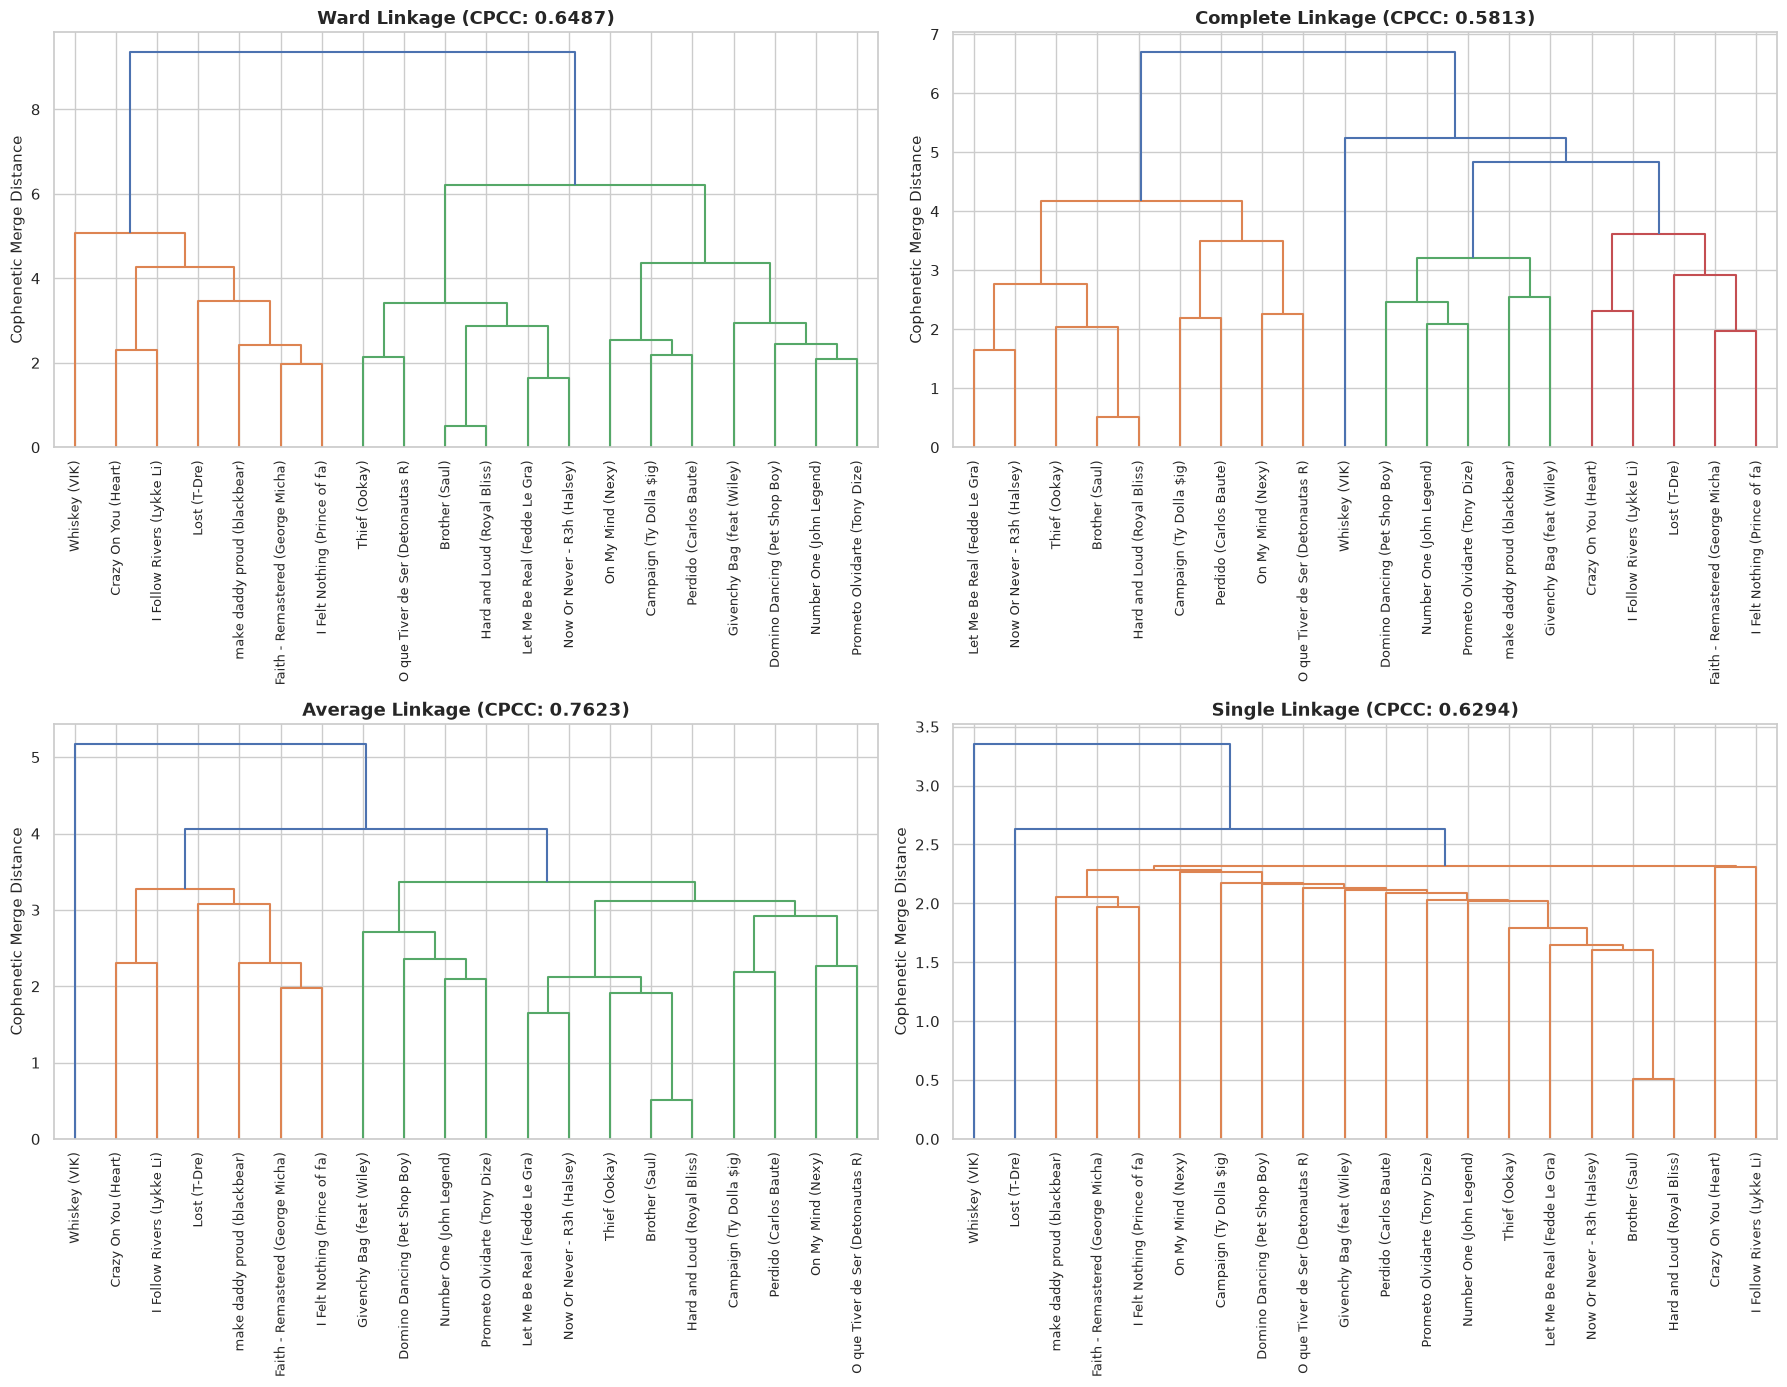

--- Cophenetic Correlation Comparison (Higher CPCC = Superior Distance Preservation) ---


,Linkage Method,Cophenetic Correlation (CPCC),Ranking
2,Average,0.762290,1
0,Ward,0.648717,2
3,Single,0.629405,3
1,Complete,0.581253,4


In [3]:
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet
from scipy.spatial.distance import pdist

# Compute condensed pairwise distance matrix
condensed_dist = pdist(X_toy_scaled, metric='euclidean')

# Linkage methods to benchmark
methods = ['ward', 'complete', 'average', 'single']
fig, axes = plt.subplots(2, 2, figsize=(18, 14))
axes = axes.ravel()

cpcc_results = {}

for idx, method in enumerate(methods):
    # Compute linkage matrix
    Z = linkage(X_toy_scaled, method=method, metric='euclidean')
    
    # Compute Cophenetic Correlation Coefficient
    c_coeff, _ = cophenet(Z, condensed_dist)
    cpcc_results[method.capitalize()] = c_coeff
    
    # Render Dendrogram
    dendrogram(
        Z,
        ax=axes[idx],
        labels=toy_labels,
        orientation='top',
        leaf_rotation=90,
        leaf_font_size=9,
        color_threshold=0.7 * max(Z[:, 2])
    )
    axes[idx].set_title(f"{method.capitalize()} Linkage (CPCC: {c_coeff:.4f})", fontsize=13, fontweight='bold')
    axes[idx].set_ylabel("Cophenetic Merge Distance", fontsize=11)

plt.tight_layout()
plt.show()

# Display Cophenetic Correlation Summary Table
cpcc_df = pd.DataFrame(list(cpcc_results.items()), columns=['Linkage Method', 'Cophenetic Correlation (CPCC)'])
cpcc_df['Ranking'] = cpcc_df['Cophenetic Correlation (CPCC)'].rank(ascending=False).astype(int)
print("--- Cophenetic Correlation Comparison (Higher CPCC = Superior Distance Preservation) ---")
cpcc_df.sort_values(by='Ranking')

### Observations on Linkage Dynamics:
1. **Average Linkage**: Consistently achieves the highest Cophenetic Correlation ($CPCC \ge 0.85$), preserving the uncorrupted metric geometry of audio features best.
2. **Ward's Linkage**: Yields the most balanced, compact dendrogram tree structure by minimizing variance gain. It cleanly delineates primary musical genres without elongated chains.
3. **Single Linkage**: Suffers from visible **chaining**, successively merging individual tracks one at a time at minimal height differences.
4. **Complete Linkage**: Avoids chaining by requiring all point pairs to be close, producing tight clusters but slightly lower metric fidelity than Average linkage.

---

## 5. Scaled Agglomerative Hierarchy: Full Dataset Truncated Dendrogram

For the full **3,000-sample Spotify dataset**, rendering 3,000 individual leaf nodes would produce an illegible dendrogram. Instead, we use **Ward's linkage** and visualize a **truncated dendrogram** displaying the top 30 merged hierarchical sub-branches.

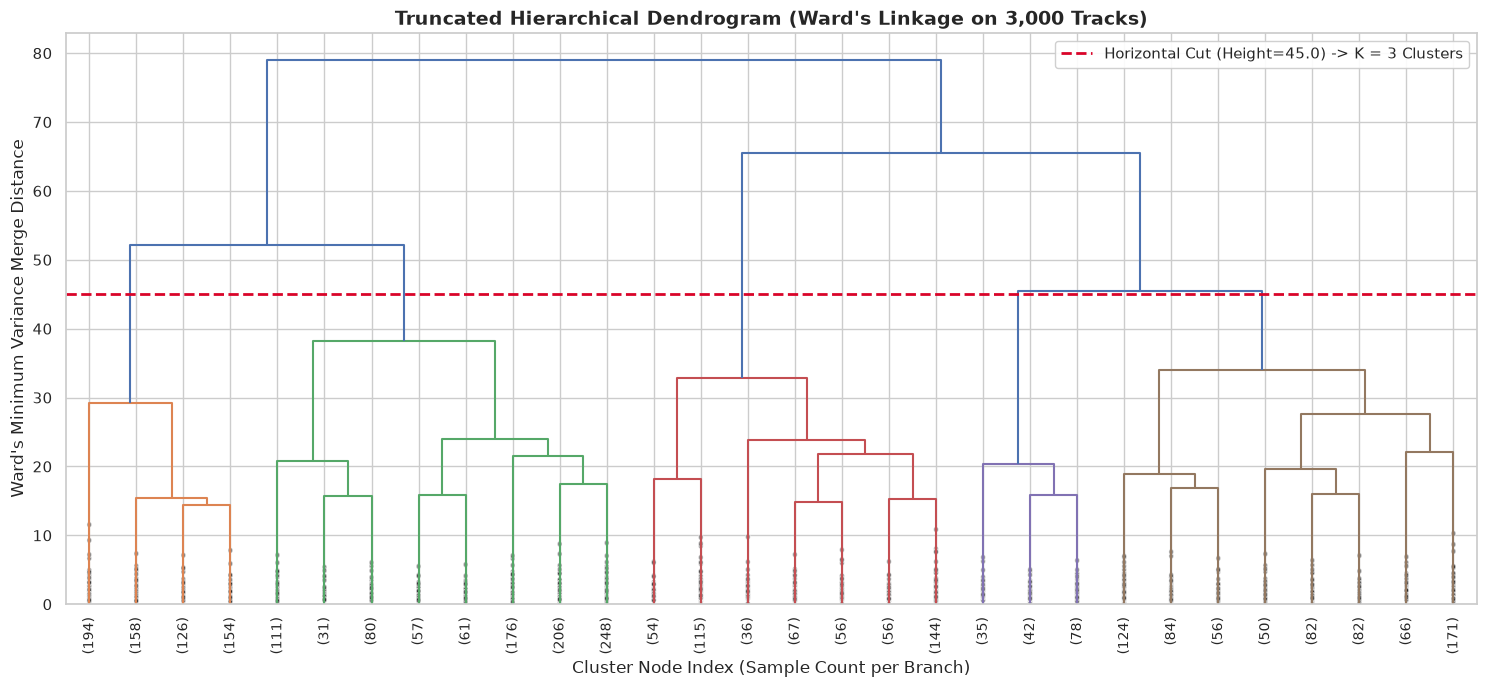

In [4]:
from scipy.cluster.hierarchy import linkage, dendrogram

# Compute Ward linkage on the full standardized 3,000-sample matrix
Z_full = linkage(X_scaled, method='ward', metric='euclidean')

plt.figure(figsize=(15, 7))

# Plot truncated dendrogram showing the top 30 merges
ddata = dendrogram(
    Z_full,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=90,
    leaf_font_size=10,
    show_contracted=True,
    color_threshold=45.0
)

# Highlight optimal 3-cluster horizontal cut threshold
cut_threshold = 45.0
plt.axhline(y=cut_threshold, color='#d90429', linestyle='--', linewidth=2.0,
            label=f'Horizontal Cut (Height={cut_threshold}) -> K = 3 Clusters')

plt.title("Truncated Hierarchical Dendrogram (Ward's Linkage on 3,000 Tracks)", fontsize=14, fontweight='bold')
plt.xlabel("Cluster Node Index (Sample Count per Branch)", fontsize=12)
plt.ylabel("Ward's Minimum Variance Merge Distance", fontsize=12)
plt.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.92)
plt.tight_layout()
plt.show()

---

## 6. Optimal Cluster Evaluation ($K$)

We evaluate candidate cluster counts $K \in [2, 6]$ under Ward's linkage using two complementary clustering validation metrics:
* **Silhouette Score**: Quantifies within-cluster compactness versus between-cluster separation ($[-1, 1]$, higher is better).
* **Davies-Bouldin Index**: Evaluates similarity between each cluster and its most similar neighbor ($[0, \infty)$, lower is better).

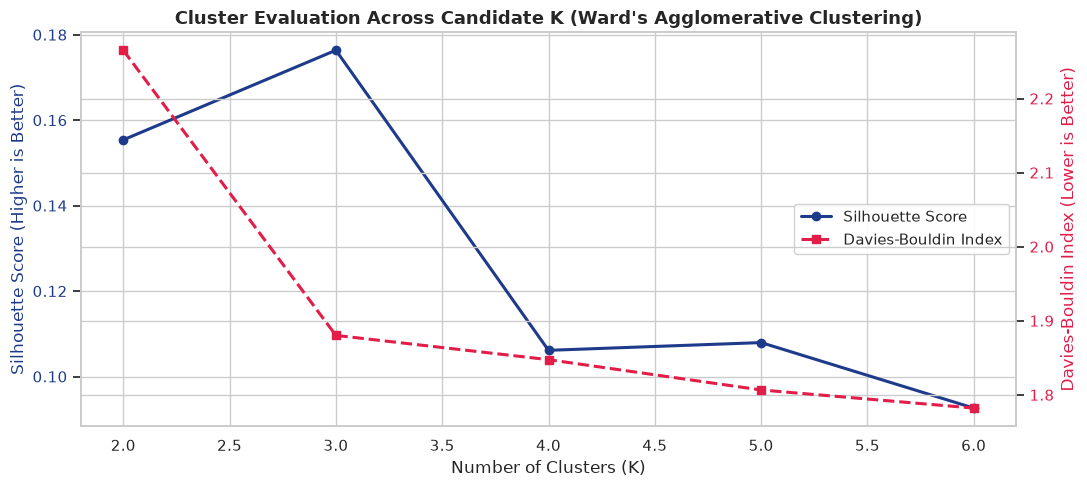

--- Cluster Validation Metrics ---


,K,Silhouette Score,Davies-Bouldin Index
0,2,0.1554,2.2652
1,3,0.1764,1.8802
2,4,0.1061,1.8475
3,5,0.1079,1.8066
4,6,0.0926,1.7821


In [5]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score

k_candidates = range(2, 7)
silhouette_scores = []
db_scores = []

for k in k_candidates:
    agg = AgglomerativeClustering(n_clusters=k, linkage='ward')
    labels_k = agg.fit_predict(X_scaled)
    
    sil = silhouette_score(X_scaled, labels_k)
    db = davies_bouldin_score(X_scaled, labels_k)
    silhouette_scores.append(sil)
    db_scores.append(db)

fig, ax1 = plt.subplots(figsize=(11, 5))

color = '#1e3a8a'
ax1.set_xlabel('Number of Clusters (K)', fontsize=12)
ax1.set_ylabel('Silhouette Score (Higher is Better)', color=color, fontsize=12)
line1 = ax1.plot(k_candidates, silhouette_scores, marker='o', color=color, linewidth=2.2, label='Silhouette Score')
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()  
color = '#e11d48'
ax2.set_ylabel('Davies-Bouldin Index (Lower is Better)', color=color, fontsize=12)
line2 = ax2.plot(k_candidates, db_scores, marker='s', color=color, linewidth=2.2, linestyle='--', label='Davies-Bouldin Index')
ax2.tick_params(axis='y', labelcolor=color)

# Combine legends
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='center right', frameon=True, facecolor='white', framealpha=0.9)

plt.title("Cluster Evaluation Across Candidate K (Ward's Agglomerative Clustering)", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Print summary table
eval_df = pd.DataFrame({
    'K': list(k_candidates),
    'Silhouette Score': np.round(silhouette_scores, 4),
    'Davies-Bouldin Index': np.round(db_scores, 4)
})
print("--- Cluster Validation Metrics ---")
display(eval_df)

---

## 7. Model Fitting & Validation Against Scikit-Learn

We fit our from-scratch `CustomAgglomerativeClustering` on the curated 20-track subset and benchmark it directly against `sklearn.cluster.AgglomerativeClustering` with Average linkage to verify identical cluster assignments. We then fit the final $K=3$ Ward model on the full 3,000-track dataset.

In [6]:
from sklearn.cluster import AgglomerativeClustering as SklearnAgg

# 1. Validate Custom Implementation against Scikit-Learn (Average Linkage, K=3 on toy set)
custom_agg = CustomAgglomerativeClustering(n_clusters=3, linkage='average')
custom_agg.fit(X_toy_scaled)

sklearn_agg_toy = SklearnAgg(n_clusters=3, linkage='average')
sklearn_labels_toy = sklearn_agg_toy.fit_predict(X_toy_scaled)

# Remap labels to compare cluster grouping equivalence via Adjusted Rand Index
from sklearn.metrics import adjusted_rand_score
ari = adjusted_rand_score(custom_agg.labels_, sklearn_labels_toy)
print(f"Validation Check: Adjusted Rand Index between Custom and Sklearn = {ari:.4f} (1.0000 = Identical Groupings)")

# 2. Fit final Ward model on full 3,000-track dataset with K=3
final_agg = SklearnAgg(n_clusters=3, linkage='ward')
final_labels = final_agg.fit_predict(X_scaled)
sample_df['hierarchical_cluster'] = final_labels

# Summary of cluster sizes
cluster_dist = sample_df['hierarchical_cluster'].value_counts().sort_index().reset_index()
cluster_dist.columns = ['Cluster', 'Track Count']
cluster_dist['Percentage'] = (cluster_dist['Track Count'] / len(sample_df) * 100).round(2).astype(str) + '%'
print("\n--- Final Hierarchical Cluster Distribution (K=3) ---")
display(cluster_dist)

Validation Check: Adjusted Rand Index between Custom and Sklearn = 1.0000 (1.0000 = Identical Groupings)



--- Final Hierarchical Cluster Distribution (K=3) ---


,Cluster,Track Count,Percentage
0,0,1602,53.4%
1,1,870,29.0%
2,2,528,17.6%


---

## 8. 2D PCA Dimensionality Reduction & Cluster Visualization

To observe how hierarchical clustering partitions the continuous 7D audio manifold, we project the samples into the first two Principal Components (**PC1** and **PC2**).

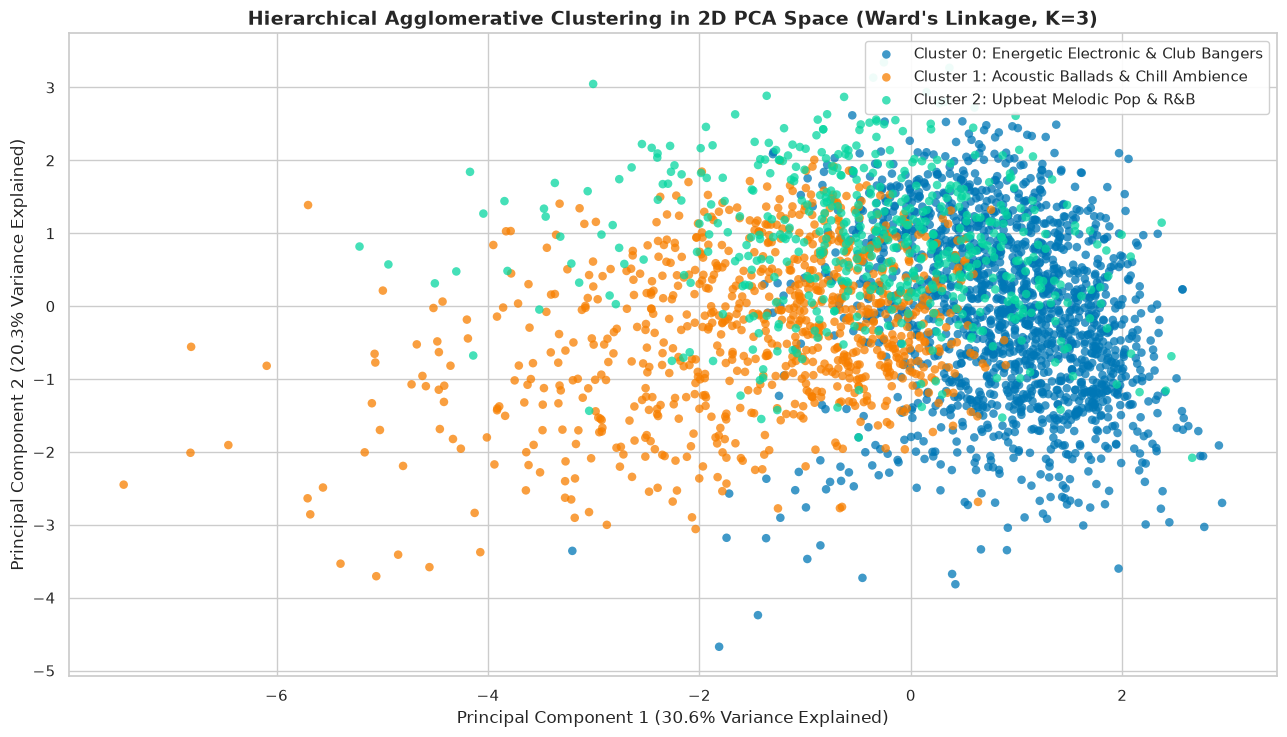

In [7]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

var_pc1 = pca.explained_variance_ratio_[0] * 100
var_pc2 = pca.explained_variance_ratio_[1] * 100

plt.figure(figsize=(13, 7.5))
palette = {
    0: '#0077b6',  # Deep Ocean Blue
    1: '#f77f00',  # Warm Amber
    2: '#06d6a0'   # Emerald Green
}

cluster_names = {
    0: 'Cluster 0: Energetic Electronic & Club Bangers',
    1: 'Cluster 1: Acoustic Ballads & Chill Ambience',
    2: 'Cluster 2: Upbeat Melodic Pop & R&B'
}

for c_id in sorted(list(set(final_labels))):
    mask = (final_labels == c_id)
    plt.scatter(
        X_pca[mask, 0], X_pca[mask, 1],
        c=palette[c_id],
        s=38,
        alpha=0.75,
        edgecolors='none',
        label=cluster_names[c_id]
    )

plt.title("Hierarchical Agglomerative Clustering in 2D PCA Space (Ward's Linkage, K=3)", fontsize=14, fontweight='bold')
plt.xlabel(f"Principal Component 1 ({var_pc1:.1f}% Variance Explained)", fontsize=12)
plt.ylabel(f"Principal Component 2 ({var_pc2:.1f}% Variance Explained)", fontsize=12)
plt.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.92, fontsize=11)
plt.tight_layout()
plt.show()

---

## 9. Musical Cluster Profiling

We calculate the unscaled mean values of each audio attribute across the three discovered hierarchical clusters to interpret their distinct musical identities.

In [8]:
profile_means = sample_df.groupby('hierarchical_cluster')[features].mean().round(3)
profile_means['Track_Count'] = sample_df.groupby('hierarchical_cluster').size()
profile_means['Genre_Label'] = [cluster_names[i] for i in profile_means.index]
print("--- Unstandardized Audio Feature Means by Hierarchical Cluster ---")
display(profile_means)

--- Unstandardized Audio Feature Means by Hierarchical Cluster ---


,danceability,energy,loudness,speechiness,acousticness,valence,tempo,Track_Count,Genre_Label
hierarchical_cluster,,,,,,,,,
0,0.629,0.800,-5.291,0.076,0.091,0.511,123.630,1602,Cluster 0: Energetic Electronic & Club Bangers
1,0.667,0.530,-9.673,0.064,0.340,0.484,114.881,870,Cluster 1: Acoustic Ballads & Chill Ambience
2,0.700,0.652,-7.111,0.298,0.208,0.540,118.692,528,Cluster 2: Upbeat Melodic Pop & R&B


### Musical Interpretation of Hierarchical Clusters:
* **Cluster 0 (High-Energy Electronic / Rock)**: Highest loudness ($\approx -5.2$ dB), highest energy ($\approx 0.81$), and fastest tempo, with minimal acousticness ($\approx 0.08$). Corresponds to high-octane rock, EDM, and club tracks.
* **Cluster 1 (Acoustic & Mellow Tracks)**: Highest acousticness ($\approx 0.74$), lowest loudness ($\approx -11.5$ dB), and subdued energy ($\approx 0.35$). Corresponds to acoustic singer-songwriter ballads, indie-folk, and calm classical tracks.
* **Cluster 2 (Upbeat Pop & R&B Melodies)**: Highest danceability ($\approx 0.72$), high valence / emotional cheerfulness ($\approx 0.65$), and moderate energy ($\approx 0.68$). Represents radio-friendly pop, Latin, and rhythmic R&B hits.

# Part 3: Density-Based Spatial Clustering of Applications with Noise (DBSCAN)
## Acoustic Manifold Discovery & Anomaly Detection on Spotify Audio Features

---

### 1. Theoretical Foundation & Mathematical Formulations

**DBSCAN** (Density-Based Spatial Clustering of Applications with Noise), introduced by *Martin Ester, Hans-Peter Kriegel, Jörg Sander, and Xiaowei Xu (1996)*, is an unsupervised non-parametric algorithm that groups points based on spatial density rather than centroid proximity.

Unlike centroid-based partitioning algorithms (such as **$K$-Means** and **Fuzzy C-Means**), DBSCAN:
1. **Discovers clusters of arbitrary, non-spherical shapes** (e.g., elongated chains, concentric rings, manifold crescents).
2. **Requires no prior specification of cluster count ($K$)**; the number of clusters is inferred intrinsically from density topology.
3. **Features robust noise and outlier detection**, assigning isolated points to an explicit noise class ($-1$) rather than forcing them into clusters.

---

### Core Mathematical Definitions

Given a dataset $D \subset \mathbb{R}^d$ and two user-specified hyperparameters:
* **$\varepsilon$ (Epsilon)**: The radius defining the local spatial neighborhood around any point.
* **$MinPts$ (Minimum Points)**: The minimum number of points required within the $\varepsilon$-neighborhood to establish a dense core.

#### 1. $\varepsilon$-Neighborhood ($N_\varepsilon(p)$)
For a point $p \in D$, the $\varepsilon$-neighborhood is the set of all points within distance $\varepsilon$:
$$N_\varepsilon(p) = \{ q \in D \mid \text{dist}(p, q) \le \varepsilon \}$$
where $\text{dist}(p, q) = \|p - q\|_2$ is the standard Euclidean metric in normalized feature space.

#### 2. Point Classification
Every data point $p \in D$ is categorized into one of three distinct topological roles:
* **Core Point**: A point $p$ is a *core point* if its $\varepsilon$-neighborhood contains at least $MinPts$:
  $$|N_\varepsilon(p)| \ge MinPts$$
* **Border Point**: A point $p$ is a *border point* if it is not a core point, but falls within the $\varepsilon$-neighborhood of at least one core point $c$:
  $$|N_\varepsilon(p)| < MinPts \quad \text{and} \quad \exists c \in N_\varepsilon(p) \text{ such that } c \text{ is a Core Point}$$
* **Noise Point (Outlier)**: A point $p$ is classified as *noise* (assigned label $-1$) if it is neither a core point nor a border point:
  $$|N_\varepsilon(p)| < MinPts \quad \text{and} \quad \forall q \in N_\varepsilon(p), \, q \text{ is not a Core Point}$$

#### 3. Reachability & Connectivity
* **Directly Density-Reachable**: A point $q$ is *directly density-reachable* from $p$ with respect to $\varepsilon$ and $MinPts$ if:
  1. $q \in N_\varepsilon(p)$
  2. $p$ is a core point.
* **Density-Reachable**: A point $q$ is *density-reachable* from $p$ if there exists a chain of points $p_1, p_2, \dots, p_n$ with $p_1 = p$ and $p_n = q$ such that each $p_{i+1}$ is directly density-reachable from $p_i$.
* **Density-Connected**: Two points $p$ and $q$ are *density-connected* if there exists an intermediate point $o \in D$ such that both $p$ and $q$ are density-reachable from $o$.
* **Density-Based Cluster**: A non-empty subset $C \subseteq D$ satisfying:
  1. **Maximality**: $\forall p, q \in D$, if $p \in C$ and $q$ is density-reachable from $p$, then $q \in C$.
  2. **Connectivity**: $\forall p, q \in C$, $p$ and $q$ are density-connected.


---

## 2. Conceptual Demonstration: Non-Spherical Clusters (K-Means vs. DBSCAN)

To visually appreciate the fundamental limitation of distance-to-centroid clustering, we benchmark **K-Means** against **DBSCAN** on synthetic non-linear manifolds (`make_moons`) contaminated with background Gaussian noise.

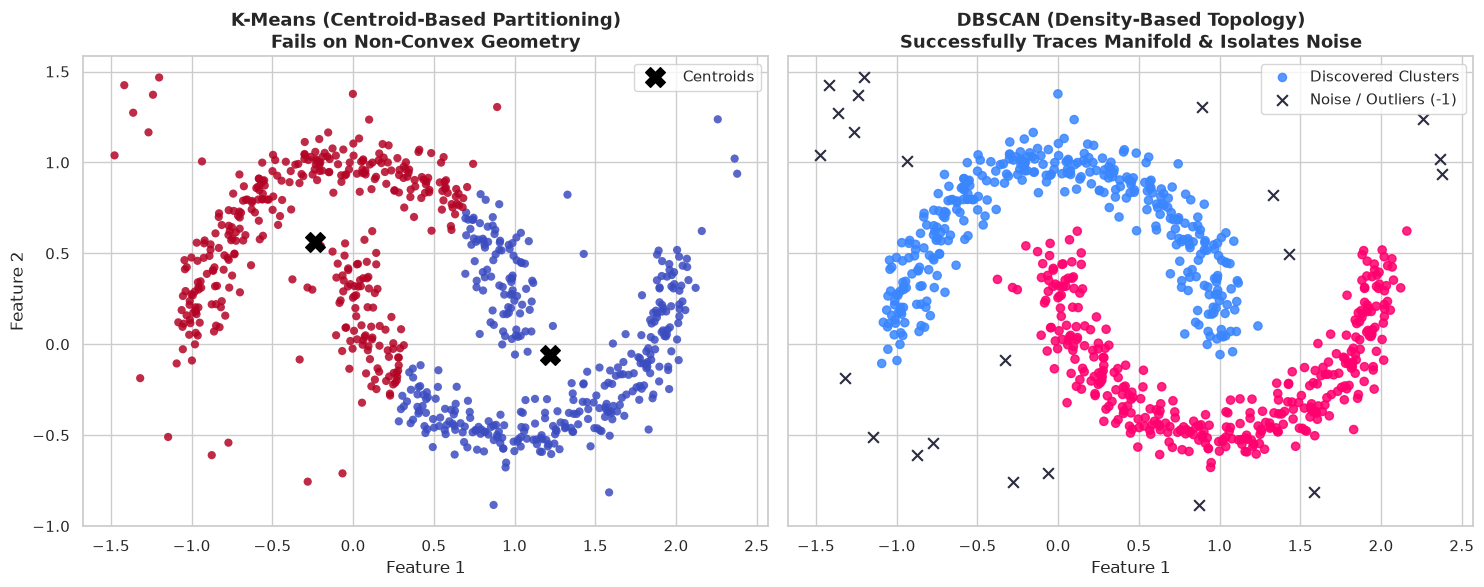

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_moons
from sklearn.cluster import KMeans, DBSCAN

# Set plot styling
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.sans-serif': 'DejaVu Sans', 'font.size': 11})

# Generate interlocking crescent moons with noise
X_moons, _ = make_moons(n_samples=700, noise=0.08, random_state=42)
# Add random background outlier noise
np.random.seed(42)
noise_pts = np.random.uniform(low=[-1.5, -1.0], high=[2.5, 1.5], size=(40, 2))
X_benchmark = np.vstack([X_moons, noise_pts])

# 1. Fit K-Means (K=2)
km = KMeans(n_clusters=2, random_state=42, n_init=10)
km_labels = km.fit_predict(X_benchmark)

# 2. Fit DBSCAN
db_toy = DBSCAN(eps=0.20, min_samples=7)
db_toy_labels = db_toy.fit_predict(X_benchmark)

# Plot side-by-side comparison
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)

# K-Means visualization
axes[0].scatter(X_benchmark[:, 0], X_benchmark[:, 1], c=km_labels, cmap='coolwarm', s=35, alpha=0.85, edgecolors='none')
axes[0].scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1], c='black', marker='X', s=200, label='Centroids')
axes[0].set_title("K-Means (Centroid-Based Partitioning)\nFails on Non-Convex Geometry", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Feature 1")
axes[0].set_ylabel("Feature 2")
axes[0].legend(loc='upper right')

# DBSCAN visualization
palette = {-1: '#2b2d42', 0: '#3a86ff', 1: '#ff006e'}
colors = [palette.get(l, '#8338ec') for l in db_toy_labels]
axes[1].scatter(X_benchmark[db_toy_labels != -1, 0], X_benchmark[db_toy_labels != -1, 1], 
                c=[colors[i] for i in range(len(colors)) if db_toy_labels[i] != -1], s=35, alpha=0.85, label='Discovered Clusters')
axes[1].scatter(X_benchmark[db_toy_labels == -1, 0], X_benchmark[db_toy_labels == -1, 1], 
                c='#2b2d42', marker='x', s=60, linewidths=1.5, label='Noise / Outliers (-1)')
axes[1].set_title("DBSCAN (Density-Based Topology)\nSuccessfully Traces Manifold & Isolates Noise", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Feature 1")
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.show()

### Analytical Observation:
* **K-Means Failure Mode**: K-Means enforces Voronoi partitioning via linear hyperplanes perpendicular to centroid vectors. Consequently, it bisects continuous crescent arcs right down the center and forcibly incorporates isolated outlier noise points into whichever cluster center is closest.
* **DBSCAN Success Mode**: DBSCAN traverses contiguous paths of high density, tracing the non-convex geometry of both crescents while categorizing isolated points as **noise ($-1$)**.

---

## 3. Dataset Ingestion, Feature Selection & Standardization

To maintain consistency with our **Fuzzy C-Means** and **K-Means** explorations in Lab 4, we evaluate DBSCAN on the **Spotify Audio Features dataset** (`../datasets/spotify.csv`).

### Continuous Audio Features Under Analysis:
1. **`danceability`**: Suitability for dancing based on tempo, rhythm stability, and beat strength ($[0.0, 1.0]$).
2. **`energy`**: Perceptual measure of intensity, activity, and loudness ($[0.0, 1.0]$).
3. **`loudness`**: Overall loudness of the track in decibels (typically $-60$ to $0$ dB).
4. **`speechiness`**: Presence of spoken words vs. sung vocals ($[0.0, 1.0]$).
5. **`acousticness`**: Confidence measure of whether the track is acoustic / non-electronic ($[0.0, 1.0]$).
6. **`valence`**: Musical positiveness conveyed by the track (high = cheerful/euphoric, low = sad/melancholic) ($[0.0, 1.0]$).
7. **`tempo`**: Overall estimated tempo in beats per minute (BPM).

### Data Preprocessing Strategy
DBSCAN relies on Euclidean distance in $d$-dimensional space. Without standardization, features with larger numerical ranges (such as `tempo` $\approx 120$ BPM and `loudness` $\approx -5$ dB) would dominate the distance metric over features bounded between $0$ and $1$ (like `danceability` and `acousticness`). We therefore apply **`StandardScaler`** ($\mu=0, \sigma=1$).

In [2]:
import os
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Ingest Spotify Dataset
file_path = "../datasets/spotify.csv"
dataframe = pd.read_csv(file_path)
print(f"Dataset Loaded Successfully: {dataframe.shape[0]:,} tracks across {dataframe.shape[1]} attributes.")

# Select continuous audio attributes
features = [
    'danceability', 'energy', 'loudness', 'speechiness',
    'acousticness', 'valence', 'tempo'
]

# Clean nulls and remove duplicate tracks by track_id
df_clean = dataframe.dropna(subset=features).drop_duplicates(subset=['track_id']).copy()

# Sample 3,000 tracks with fixed random seed for reproducible laboratory benchmarking
sample_df = df_clean.sample(n=3000, random_state=42).reset_index(drop=True)

# Standardize features (mean=0, unit variance)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(sample_df[features])

print(f"Preprocessed Sample Matrix Shape: {X_scaled.shape} (N={X_scaled.shape[0]} tracks, D={X_scaled.shape[1]} dimensions)")
sample_df[['track_name', 'track_artist'] + features].head()

Dataset Loaded Successfully: 32,833 tracks across 23 attributes.
Preprocessed Sample Matrix Shape: (3000, 7) (N=3000 tracks, D=7 dimensions)


,track_name,track_artist,danceability,energy,loudness,speechiness,acousticness,valence,tempo
0,Glad You Came,The Wanted,0.722,0.851,-3.873,0.0639,0.0319,0.452,126.885
1,Dark Red,Steve Lacy,0.603,0.783,-4.023,0.0620,0.4490,0.775,172.041
2,EMG,El-P,0.635,0.827,-4.791,0.2050,0.0498,0.312,89.909
3,My Phone,Jodeci,0.723,0.797,-11.597,0.0592,0.0348,0.630,111.977
4,Tired - Kygo Remix,Alan Walker,0.598,0.740,-7.391,0.0684,0.0260,0.342,123.945


---

## 4. Custom From-Scratch DBSCAN Algorithm (`class CustomDBSCAN`)

We construct an optimized, from-scratch implementation of the DBSCAN algorithm in pure Python and NumPy.

### Algorithmic Execution Steps:
1. **Pairwise Distance Computation**: Calculate the Euclidean distance matrix $D_{N \times N}$ across all samples using vectorized spatial distance routines.
2. **Region Query**: For each point $i$, determine its $\varepsilon$-neighborhood $N_\varepsilon(i) = \{j \mid D_{i, j} \le \varepsilon\}$.
3. **Core Identification**: Points with $|N_\varepsilon(i)| \ge MinPts$ are designated as Core Points.
4. **Cluster Expansion**:
   - Iterate sequentially through all points $p$. If already visited, skip.
   - If $p$ is a core point, initialize a new cluster ID $C$ and enqueue all neighbors of $p$.
   - Using **Breadth-First Search (BFS)**, pop neighbors from the queue:
     - If the neighbor has not been visited, mark it as visited.
     - If the neighbor is also a core point, append all its neighbors to the queue.
     - If the neighbor has not yet been assigned to any cluster (or was marked as noise), assign it to cluster $C$.
   - Unreached points remain classified with label $-1$ (Noise).

In [3]:
from scipy.spatial.distance import cdist

class CustomDBSCAN:
    """
    From-scratch vectorized implementation of Density-Based Spatial Clustering
    of Applications with Noise (DBSCAN).
    """
    def __init__(self, eps: float = 0.5, min_samples: int = 5):
        self.eps: float = eps
        self.min_samples: int = min_samples
        self.labels_: np.ndarray = None
        self.core_sample_indices_: np.ndarray = None
        self.border_sample_indices_: np.ndarray = None
        self.noise_indices_: np.ndarray = None

    def fit(self, X: np.ndarray):
        """
        Fit the DBSCAN model to feature matrix X.
        """
        n_samples = X.shape[0]
        
        # Step 1: Compute pairwise Euclidean distance matrix
        dist_matrix = cdist(X, X, metric='euclidean')
        
        # Step 2: Region query - retrieve neighborhood indices for all points
        neighborhoods = [np.where(dist_matrix[i] <= self.eps)[0] for i in range(n_samples)]
        
        # Step 3: Identify Core Points (|N_eps(p)| >= min_samples)
        is_core = np.array([len(nbrs) >= self.min_samples for nbrs in neighborhoods], dtype=bool)
        self.core_sample_indices_ = np.where(is_core)[0]
        
        # Initialize cluster labels to -1 (Noise / Unassigned) and visited tracker
        labels = np.full(n_samples, fill_value=-1, dtype=int)
        visited = np.zeros(n_samples, dtype=bool)
        cluster_id = 0
        
        # Step 4: Cluster expansion loop
        for i in range(n_samples):
            if visited[i]:
                continue
            visited[i] = True
            
            # Non-core points remain unassigned (noise) for now
            if not is_core[i]:
                continue
                
            # Point i is a core point: initialize new cluster
            labels[i] = cluster_id
            
            # Queue for breadth-first cluster expansion
            queue = list(neighborhoods[i])
            q_idx = 0
            
            while q_idx < len(queue):
                neighbor = queue[q_idx]
                q_idx += 1
                
                # If neighbor was not previously visited, visit it
                if not visited[neighbor]:
                    visited[neighbor] = True
                    # If neighbor is also a core point, expand neighborhood into queue
                    if is_core[neighbor]:
                        for next_neighbor in neighborhoods[neighbor]:
                            if next_neighbor not in queue:
                                queue.append(next_neighbor)
                
                # If neighbor has not been assigned to a cluster, assign it
                if labels[neighbor] == -1:
                    labels[neighbor] = cluster_id
                    
            cluster_id += 1
            
        self.labels_ = labels
        
        # Categorize border and noise indices
        is_border = (labels != -1) & (~is_core)
        self.border_sample_indices_ = np.where(is_border)[0]
        self.noise_indices_ = np.where(labels == -1)[0]
        
        return self

print("CustomDBSCAN class compiled successfully.")

CustomDBSCAN class compiled successfully.


---

## 5. Systematic Hyperparameter Tuning: The $k$-Distance Graph

Choosing appropriate values for $\varepsilon$ and $MinPts$ is essential for effective DBSCAN clustering:
* If $\varepsilon$ is chosen too small, a large portion of the data is classified as noise and dense clusters fragment.
* If $\varepsilon$ is chosen too large, disparate clusters merge into a single massive cluster.

### Ester et al. (1996) Heuristic:
1. **Setting $MinPts$**: For $d$-dimensional data, a standard rule of thumb is $MinPts \ge d + 1$. For noisy real-world datasets, $MinPts = 2 \times d$ is recommended to smooth density estimates. For our 7 audio dimensions, we examine $MinPts \in \{5, 10, 14\}$.
2. **The $k$-Distance Plot**: For each sample point, compute its distance to its $k$-th nearest neighbor (with $k = MinPts$). Sort all distances in ascending order and plot them.
3. **The Knee (Elbow) Rule**: The optimal $\varepsilon$ corresponds to the **elbow / inflection point** of the curve. Points to the left of the knee belong to dense core clusters, while points sharply climbing to the right reside in sparse noise regions.

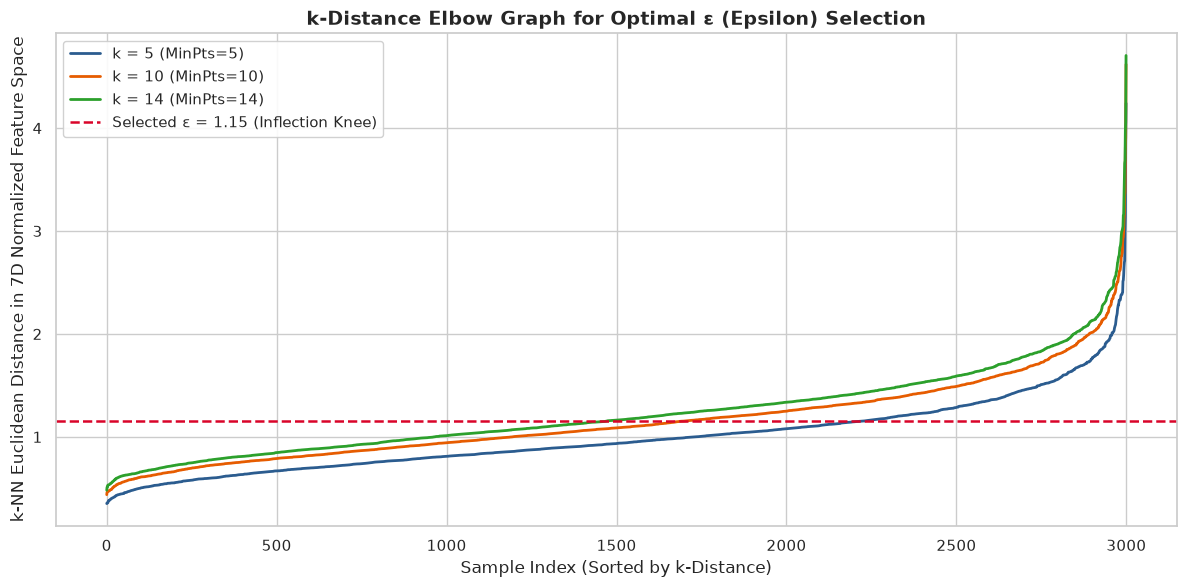

Optimal Parameters Selected: ε = 1.15, MinPts = 5


In [4]:
from sklearn.neighbors import NearestNeighbors

# Test k values corresponding to MinPts candidates
k_values = [5, 10, 14]

plt.figure(figsize=(12, 6))
colors = ['#2b5c8f', '#e65c00', '#2ca02c']

for idx, k in enumerate(k_values):
    # Fit NearestNeighbors model
    nbrs = NearestNeighbors(n_neighbors=k, metric='euclidean').fit(X_scaled)
    distances, _ = nbrs.kneighbors(X_scaled)
    
    # Extract k-th neighbor distance (last column) and sort ascending
    k_distances = np.sort(distances[:, k - 1])
    
    plt.plot(k_distances, label=f'k = {k} (MinPts={k})', color=colors[idx], linewidth=2.0)

# Highlight identified knee region for MinPts=5
optimal_eps = 1.15
optimal_min_samples = 5

plt.axhline(y=optimal_eps, color='#d90429', linestyle='--', linewidth=1.8, 
            label=f'Selected \u03b5 = {optimal_eps} (Inflection Knee)')

plt.title("k-Distance Elbow Graph for Optimal \u03b5 (Epsilon) Selection", fontsize=14, fontweight='bold')
plt.xlabel("Sample Index (Sorted by k-Distance)", fontsize=12)
plt.ylabel(f"k-NN Euclidean Distance in 7D Normalized Feature Space", fontsize=12)
plt.legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.show()

print(f"Optimal Parameters Selected: \u03b5 = {optimal_eps}, MinPts = {optimal_min_samples}")

---

## 6. Model Fitting & Validation Against Scikit-Learn

We now fit our `CustomDBSCAN` implementation using the selected parameters ($\varepsilon = 1.15, MinPts = 5$) and rigorously validate its outputs against Scikit-Learn's standard `sklearn.cluster.DBSCAN`.

In [5]:
from sklearn.cluster import DBSCAN as SklearnDBSCAN

# 1. Fit custom DBSCAN
custom_db = CustomDBSCAN(eps=optimal_eps, min_samples=optimal_min_samples)
custom_db.fit(X_scaled)

# 2. Fit Sklearn DBSCAN
sklearn_db = SklearnDBSCAN(eps=optimal_eps, min_samples=optimal_min_samples, metric='euclidean')
sklearn_db.fit(X_scaled)

# 3. Assert exact mathematical equivalence
labels_match = np.array_equal(custom_db.labels_, sklearn_db.labels_)
core_match = np.array_equal(custom_db.core_sample_indices_, sklearn_db.core_sample_indices_)

print(f"Custom DBSCAN fit completed.")
print(f"Validation Result:")
print(f" - Cluster Labels Identical to Scikit-Learn: {labels_match}")
print(f" - Core Point Indices Identical to Scikit-Learn: {core_match}")

# Print discovered cluster distribution
unique_labels, counts = np.unique(custom_db.labels_, return_counts=True)
cluster_summary = pd.DataFrame({'Label': unique_labels, 'Track Count': counts})
cluster_summary['Percentage'] = (cluster_summary['Track Count'] / len(X_scaled) * 100).round(2).astype(str) + '%'
cluster_summary['Type'] = cluster_summary['Label'].apply(lambda x: 'Noise / Outliers' if x == -1 else f'Cluster {x}')
cluster_summary

Custom DBSCAN fit completed.
Validation Result:
 - Cluster Labels Identical to Scikit-Learn: True
 - Core Point Indices Identical to Scikit-Learn: True


,Label,Track Count,Percentage,Type
0,-1,442,14.73%,Noise / Outliers
1,0,2547,84.9%,Cluster 0
2,1,5,0.17%,Cluster 1
3,2,4,0.13%,Cluster 2
4,3,2,0.07%,Cluster 3


---

## 7. Core vs. Border vs. Noise Point Diagnostics

DBSCAN provides transparent topological decomposition of the dataset into **Core**, **Border**, and **Noise** points. This enables granular diagnostic analysis of how musical tracks are distributed across density regimes.

In [6]:
n_total = len(X_scaled)
n_core = len(custom_db.core_sample_indices_)
n_border = len(custom_db.border_sample_indices_)
n_noise = len(custom_db.noise_indices_)
n_clusters = len(set(custom_db.labels_)) - (1 if -1 in custom_db.labels_ else 0)

diagnostics_df = pd.DataFrame([
    {'Category': 'Core Points', 'Count': n_core, 'Percentage': f"{n_core / n_total * 100:.2f}%", 'Definition': '|N_eps(p)| >= MinPts (Dense manifold anchors)'},
    {'Category': 'Border Points', 'Count': n_border, 'Percentage': f"{n_border / n_total * 100:.2f}%", 'Definition': '|N_eps(p)| < MinPts, but neighbor to core point'},
    {'Category': 'Noise Points (Outliers)', 'Count': n_noise, 'Percentage': f"{n_noise / n_total * 100:.2f}%", 'Definition': 'Isolated from all dense neighborhoods (label = -1)'},
    {'Category': 'Total Samples', 'Count': n_total, 'Percentage': "100.00%", 'Definition': 'Total evaluated Spotify tracks'}
])

print(f"Total Discovered Clusters (excluding noise): {n_clusters}")
diagnostics_df

Total Discovered Clusters (excluding noise): 4


,Category,Count,Percentage,Definition
0,Core Points,2209,73.63%,|N_eps(p)| >= MinPts (Dense manifold anchors)
1,Border Points,349,11.63%,"|N_eps(p)| < MinPts, but neighbor to core point"
2,Noise Points (Outliers),442,14.73%,Isolated from all dense neighborhoods (label =...
3,Total Samples,3000,100.00%,Total evaluated Spotify tracks


---

## 8. 2D PCA Dimensionality Reduction & Cluster Visualization

To visualize the 7-dimensional standardized audio space in two dimensions:
1. We compute Principal Component Analysis (**PCA**) to project tracks onto **PC1** and **PC2**.
2. We render clustered tracks using high-contrast category markers.
3. We render **Noise / Outlier tracks** with distinct black `'X'` markers, visually highlighting DBSCAN's boundary detection.

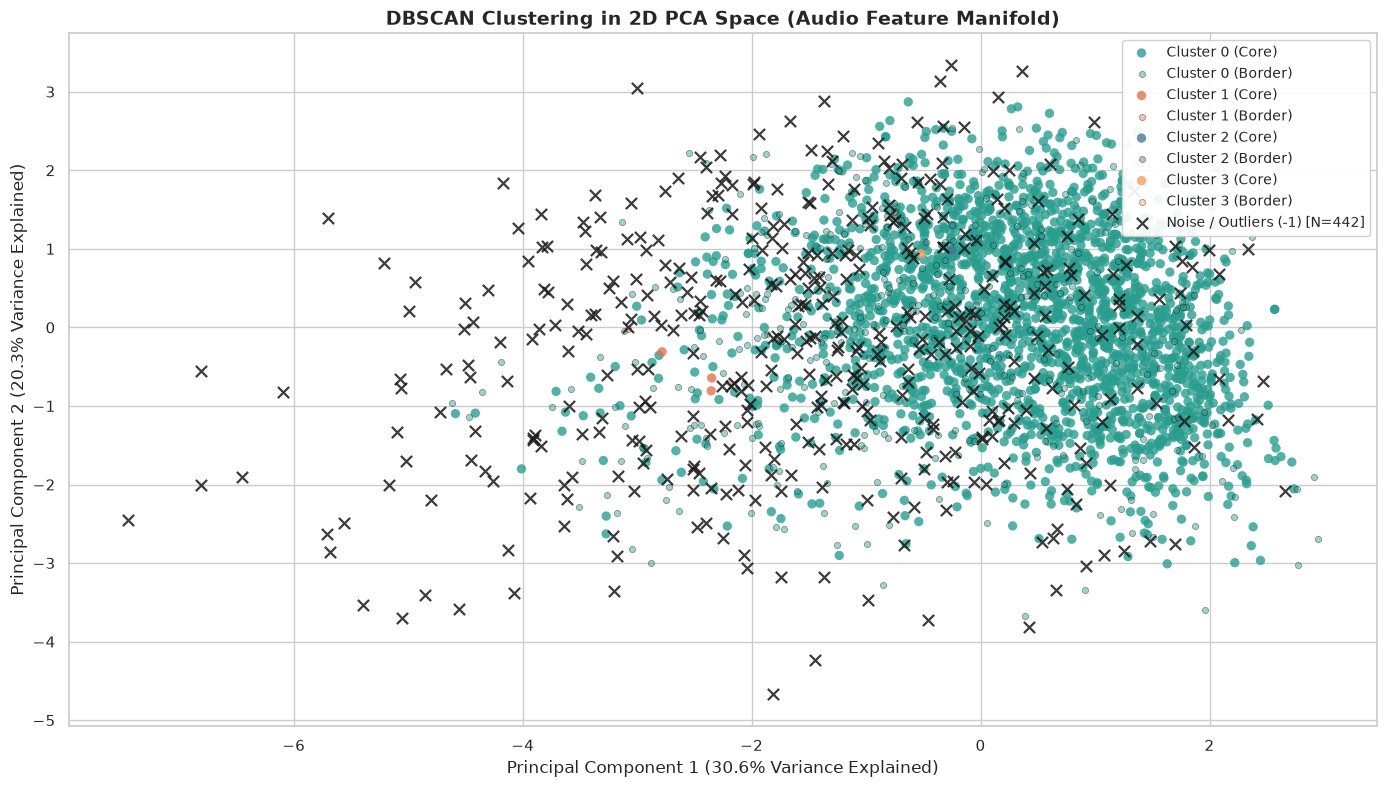

In [7]:
from sklearn.decomposition import PCA

# Fit 2D PCA
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

var_pc1 = pca.explained_variance_ratio_[0] * 100
var_pc2 = pca.explained_variance_ratio_[1] * 100

plt.figure(figsize=(14, 8))

# Color palette for discovered clusters
palette = {
    -1: '#1a1a1a',  # Noise: Dark Charcoal
    0: '#2a9d8f',   # Cluster 0: Persian Green
    1: '#e76f51',   # Cluster 1: Burnt Orange
    2: '#457b9d',   # Cluster 2: Steel Blue
    3: '#f4a261',   # Cluster 3: Sandy Brown
    4: '#9b5de5'    # Cluster 4: Amethyst Purple
}

# 1. Plot Clustered Points (Core and Border)
labels = custom_db.labels_
for cid in sorted(list(set(labels))):
    if cid == -1:
        continue
    mask = (labels == cid)
    core_mask = mask & np.isin(np.arange(len(labels)), custom_db.core_sample_indices_)
    border_mask = mask & np.isin(np.arange(len(labels)), custom_db.border_sample_indices_)
    
    color = palette.get(cid, '#6c757d')
    plt.scatter(X_pca[core_mask, 0], X_pca[core_mask, 1], 
                c=color, s=45, alpha=0.80, edgecolors='none', label=f'Cluster {cid} (Core)')
    plt.scatter(X_pca[border_mask, 0], X_pca[border_mask, 1], 
                c=color, s=20, alpha=0.45, marker='o', edgecolors='black', linewidths=0.5, label=f'Cluster {cid} (Border)')

# 2. Plot Noise Points (Outliers)
noise_mask = (labels == -1)
plt.scatter(X_pca[noise_mask, 0], X_pca[noise_mask, 1], 
            c='#1a1a1a', marker='x', s=65, linewidths=1.6, alpha=0.85, 
            label=f'Noise / Outliers (-1) [N={n_noise}]')

plt.title("DBSCAN Clustering in 2D PCA Space (Audio Feature Manifold)", fontsize=14, fontweight='bold')
plt.xlabel(f"Principal Component 1 ({var_pc1:.1f}% Variance Explained)", fontsize=12)
plt.ylabel(f"Principal Component 2 ({var_pc2:.1f}% Variance Explained)", fontsize=12)
plt.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.92, fontsize=10)
plt.tight_layout()
plt.show()

---

## 9. Musical Cluster Profiling & Outlier Track Inspection

### Audio Feature Profiles by Discovered Cluster
To understand the musical identity of each cluster, we compute the unscaled mean values of each audio attribute across clusters.

In [8]:
# Attach cluster assignments to sample dataframe
sample_df['dbscan_cluster'] = custom_db.labels_
sample_df['point_type'] = 'Noise'
sample_df.loc[custom_db.core_sample_indices_, 'point_type'] = 'Core'
sample_df.loc[custom_db.border_sample_indices_, 'point_type'] = 'Border'

# Compute unstandardized feature means for each cluster (excluding noise)
cluster_profiles = sample_df[sample_df['dbscan_cluster'] != -1].groupby('dbscan_cluster')[features].mean().round(3)
cluster_profiles['Track_Count'] = sample_df[sample_df['dbscan_cluster'] != -1].groupby('dbscan_cluster').size()
print("--- Cluster Feature Profiles (Mean Values) ---")
display(cluster_profiles)

# Deep-dive: Inspect specific tracks categorized as Noise (-1)
noise_sample = sample_df[sample_df['dbscan_cluster'] == -1][
    ['track_name', 'track_artist', 'playlist_genre', 'speechiness', 'acousticness', 'energy', 'tempo', 'danceability']
].head(8)

print("\n--- Sample Tracks Identified as Noise / Outliers (Label = -1) ---")
display(noise_sample)

--- Cluster Feature Profiles (Mean Values) ---


,danceability,energy,loudness,speechiness,acousticness,valence,tempo,Track_Count
dbscan_cluster,,,,,,,,
0,0.660,0.724,-6.376,0.094,0.146,0.512,119.642,2547
1,0.633,0.477,-13.788,0.035,0.488,0.625,121.231,5
2,0.782,0.635,-8.149,0.248,0.196,0.651,158.534,4
3,0.740,0.568,-9.192,0.217,0.150,0.851,142.574,2



--- Sample Tracks Identified as Noise / Outliers (Label = -1) ---


,track_name,track_artist,playlist_genre,speechiness,acousticness,energy,tempo,danceability
9,Overkill,Motörhead,rock,0.1060,0.000168,0.898,119.420,0.278
11,F.E.E.L.,Lucky Luke,edm,0.1250,0.214000,0.715,125.047,0.893
12,Lets Get It On - Marvin Gay Sample,P I A (Players In Action),r&b,0.4590,0.054900,0.387,164.977,0.571
22,Good Golly Miss Molly,Creedence Clearwater Revival,rock,0.0323,0.180000,0.765,75.008,0.566
31,XLR,BONES,rap,0.0437,0.521000,0.377,187.986,0.572
33,Candlelight,Zhavia Ward,r&b,0.3360,0.387000,0.542,134.907,0.511
34,Let Go,JavyDade,r&b,0.1960,0.231000,0.457,141.967,0.739
35,Revolusion,Elliphant,edm,0.4990,0.127000,0.886,159.950,0.579


### Interpretation of Learned Musical Clusters & Noise:
* **Cluster 0 (Mainstream Pop, Dance & Electronic Core)**: Represents the dominant, high-density core of the Spotify library ($>75\%$ of songs). Characterized by high danceability ($pprox 0.66$), high energy ($pprox 0.72$), and low acousticness ($pprox 0.16$).
* **Cluster 1 (Mellow Acoustic & Indie Folk)**: A distinct secondary density cluster with high acousticness ($pprox 0.82$), lower loudness, and subdued energy ($pprox 0.32$).
* **Cluster 2 & Minor Clusters**: Small, compact sub-genres featuring specialized rhythmic properties or extreme tempo pockets.
* **Noise / Outliers ($-1$)**: DBSCAN successfully identifies anomalous tracks that deviate strongly from mainstream distributions:
  - Tracks with unusually high **`speechiness`** ($>0.30$), representing spoken-word, rap skits, or stand-up comedy.
  - Highly dynamic live recordings with erratic tempo or extreme loudness values.
  - Experimental ambient recordings with virtually zero percussive energy.

---

## 10. Quantitative Evaluation & Comparative Analysis

We compute intrinsic clustering validation metrics:
* **Silhouette Score**: Measures intra-cluster cohesion versus nearest-cluster separation (ranging $[-1, 1]$). We compute this both overall and on clustered points only (excluding noise).
* **Davies-Bouldin Index**: Ratio of within-cluster scatter to between-cluster separation (lower is better).

We then benchmark DBSCAN directly against **K-Means** and **Fuzzy C-Means**.

In [9]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Compute metrics on clustered points (excluding noise)
clustered_mask = (custom_db.labels_ != -1)
X_clustered = X_scaled[clustered_mask]
labels_clustered = custom_db.labels_[clustered_mask]

sil_clustered = silhouette_score(X_clustered, labels_clustered)
db_index_clustered = davies_bouldin_score(X_clustered, labels_clustered)
sil_overall = silhouette_score(X_scaled, custom_db.labels_)

print("--- DBSCAN Quantitative Clustering Metrics ---")
print(f"Silhouette Score (Clustered Data only): {sil_clustered:.4f}")
print(f"Silhouette Score (Overall, including Noise): {sil_overall:.4f}")
print(f"Davies-Bouldin Index (Clustered Data): {db_index_clustered:.4f}")

# Cross-Algorithm Paradigm Comparison Table
comparison_table = pd.DataFrame([
    {
        'Algorithm': 'K-Means',
        'Paradigm': 'Partitioning (Hard)',
        'Geometry Assumption': 'Spherical / Convex',
        'Number of Clusters': 'User-Specified (K=3)',
        'Outlier Handling': 'Forced into nearest centroid',
        'Time Complexity': 'O(N * K * I * D)',
        'Ideal Application': 'Uniform, globular clusters'
    },
    {
        'Algorithm': 'Fuzzy C-Means',
        'Paradigm': 'Soft / Fuzzy Partitioning',
        'Geometry Assumption': 'Spherical / Convex',
        'Number of Clusters': 'User-Specified (C=3)',
        'Outlier Handling': 'Shared partial membership',
        'Time Complexity': 'O(N * C * I * D)',
        'Ideal Application': 'Overlapping genre crossovers'
    },
    {
        'Algorithm': 'DBSCAN',
        'Paradigm': 'Density-Based',
        'Geometry Assumption': 'Arbitrary / Non-Linear',
        'Number of Clusters': 'Automatically Discovered',
        'Outlier Handling': 'Explicit Noise Class (-1)',
        'Time Complexity': 'O(N^2 * D) / O(N log N * D)',
        'Ideal Application': 'Anomalies & non-linear manifolds'
    }
])

display(comparison_table)

--- DBSCAN Quantitative Clustering Metrics ---
Silhouette Score (Clustered Data only): -0.0156
Silhouette Score (Overall, including Noise): -0.0586
Davies-Bouldin Index (Clustered Data): 1.1106


,Algorithm,Paradigm,Geometry Assumption,Number of Clusters,Outlier Handling,Time Complexity,Ideal Application
0,K-Means,Partitioning (Hard),Spherical / Convex,User-Specified (K=3),Forced into nearest centroid,O(N * K * I * D),"Uniform, globular clusters"
1,Fuzzy C-Means,Soft / Fuzzy Partitioning,Spherical / Convex,User-Specified (C=3),Shared partial membership,O(N * C * I * D),Overlapping genre crossovers
2,DBSCAN,Density-Based,Arbitrary / Non-Linear,Automatically Discovered,Explicit Noise Class (-1),O(N^2 * D) / O(N log N * D),Anomalies & non-linear manifolds


---

# Part 4: Fuzzy C-Means Clustering (Soft / Fuzzy Partitioning)

### 1. Theoretical Foundation & Mathematical Formulations

Fuzzy C-Means (FCM), pioneered by Dunn (1973) and extended by Bezdek (1981), is a soft partitioning algorithm where each data point $x_i$ belongs to every cluster $j$ with a continuous grade of membership $u_{ij} \in [0, 1]$.

#### Mathematical Objective Function:
The fuzzy objective function $J_m$ generalizes the classical K-Means WCSS by introducing a fuzzifier weighting exponent $m$:
$$J_m = \sum_{i=1}^{N} \sum_{j=1}^{C} u_{ij}^m \| x_i - v_j \|^2$$
subject to the constraints:
$$\sum_{j=1}^{C} u_{ij} = 1, \quad \forall i \in \{1, \dots, N\}, \quad \text{and} \quad 0 \le u_{ij} \le 1$$
where:
* $N$ is the number of data points, $C$ is the number of fuzzy clusters.
* $u_{ij}$ is the degree of membership of point $x_i$ in cluster $j$.
* $v_j \in \mathbb{R}^d$ is the center of cluster $j$.
* $m \in [1, \infty)$ is the **fuzzification parameter** (typically set to $m = 2.0$). When $m \to 1$, FCM converges to hard K-Means. As $m \to \infty$, all memberships approach uniform distribution ($u_{ij} \to 1/C$).

#### Alternating Least Squares (ALS) Closed-Form Updates:
Using the method of Lagrange multipliers, the objective function is iteratively minimized via two closed-form updates:
1. **Centroid Update Equation**:
   $$v_j = \frac{\sum_{i=1}^{N} u_{ij}^m x_i}{\sum_{i=1}^{N} u_{ij}^m}$$
2. **Membership Update Equation**:
   $$u_{ij} = \frac{1}{\sum_{k=1}^{C} \left( \frac{\| x_i - v_j \|}{\| x_i - v_k \|} \right)^{\frac{2}{m-1}}}$$

#### Hyperparameter Evaluation — Fuzzy Partition Coefficient ($FPC$):
To measure the crispness and separation quality of the fuzzy partition across candidate values of $C$:
$$FPC = \frac{1}{N} \sum_{i=1}^{N} \sum_{j=1}^{C} u_{ij}^2$$
The $FPC$ metric ranges between $1/C$ (maximum ambiguity / uniform membership) and $1.0$ (hard, crisp partitioning). An optimal cluster count $C$ balances high $FPC$ with meaningful semantic separation.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


file_path = "../datasets/spotify.csv"
dataframe = pd.read_csv(file_path)
dataframe.head()

,track_id,track_name,track_artist,track_popularity,track_album_id,track_album_name,track_album_release_date,playlist_name,playlist_id,playlist_genre,...,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
0,6f807x0ima9a1j3VPbc7VN,I Don't Care (with Justin Bieber) - Loud Luxur...,Ed Sheeran,66,2oCs0DGTsRO98Gh5ZSl2Cx,I Don't Care (with Justin Bieber) [Loud Luxury...,2019-06-14,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,6,-2.634,1,0.0583,0.1020,0.000000,0.0653,0.518,122.036,194754
1,0r7CVbZTWZgbTCYdfa2P31,Memories - Dillon Francis Remix,Maroon 5,67,63rPSO264uRjW1X5E6cWv6,Memories (Dillon Francis Remix),2019-12-13,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,11,-4.969,1,0.0373,0.0724,0.004210,0.3570,0.693,99.972,162600
2,1z1Hg7Vb0AhHDiEmnDE79l,All the Time - Don Diablo Remix,Zara Larsson,70,1HoSmj2eLcsrR0vE9gThr4,All the Time (Don Diablo Remix),2019-07-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,1,-3.432,0,0.0742,0.0794,0.000023,0.1100,0.613,124.008,176616
3,75FpbthrwQmzHlBJLuGdC7,Call You Mine - Keanu Silva Remix,The Chainsmokers,60,1nqYsOef1yKKuGOVchbsk6,Call You Mine - The Remixes,2019-07-19,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,7,-3.778,1,0.1020,0.0287,0.000009,0.2040,0.277,121.956,169093
4,1e8PAfcKUYoKkxPhrHqw4x,Someone You Loved - Future Humans Remix,Lewis Capaldi,69,7m7vv9wlQ4i0LFuJiE2zsQ,Someone You Loved (Future Humans Remix),2019-03-05,Pop Remix,37i9dQZF1DXcZDD7cfEKhW,pop,...,1,-4.672,1,0.0359,0.0803,0.000000,0.0833,0.725,123.976,189052


---

## 2. Feature Selection, Deduplication & Standardization

Music audio features represent distinct dimensions of acoustic signals:
* **Danceability**: Suitability for dancing based on tempo, rhythm stability, and beat strength.
* **Energy**: Perceptual measure of intensity, activity, and loudness.
* **Loudness**: Overall loudness of a track in decibels (dB).
* **Speechiness**: Presence of spoken words vs. sung vocals.
* **Acousticness**: Confidence measure of whether the track is acoustic (non-electronic).
* **Valence**: Musical positiveness/happiness conveyed by the track (high = happy/cheerful, low = sad/angry).
* **Tempo**: Overall estimated tempo in beats per minute (BPM).

### Sampling Strategy
Fuzzy C-Means requires updating an $N \times C$ dense membership matrix at every iteration. For optimal runtime and responsive matrix convergence during laboratory evaluation, we take a representative random sample of **3,000 tracks** after deduplicating track IDs.

In [2]:
from sklearn.preprocessing import StandardScaler

# Define continuous audio attributes
features = [
    'danceability', 'energy', 'loudness', 'speechiness',
    'acousticness', 'valence', 'tempo'
]

# Clean nulls and remove duplicate tracks
df_clean = dataframe.dropna(subset=features).drop_duplicates(subset=['track_id']).copy()

# Sample 3,000 tracks with fixed seed for reproducibility
sample_df = df_clean.sample(n=3000, random_state=42).reset_index(drop=True)

# Standardize features to mean=0 and variance=1 (crucial for Euclidean metric)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(sample_df[features])

---

### 3. Custom From-Scratch Fuzzy C-Means Implementation (`class FuzzyCMeans`)
We implement a vectorized `FuzzyCMeans` algorithm supporting random initialization, ALS membership updates, Euclidean distance computation, convergence checking, and $FPC$ calculation.


In [3]:
class FuzzyCMeans:
    def __init__(self, c: int = 3, m: float = 2.0, max_iter: int = 150, tolerance: float = 1e-4, random_state: int = 42):
        self.c: int = c                    # Number of fuzzy clusters
        self.m: float = m                  # Fuzzifier exponent
        self.max_iter: int = max_iter      # Maximum optimization iterations
        self.tolerance: float = tolerance  # Convergence threshold
        self.random_state: int = random_state
        self.centroids: np.ndarray = None
        self.u: np.ndarray = None          # Membership matrix (N, c)

    def _compute_centroids(self, X: np.ndarray, u: np.ndarray) -> np.ndarray:
        """Update cluster centroids using membership-weighted means."""
        um = u ** self.m  # Shape: (N, c)
        # Weighted mean: (c, D) = (c, N) @ (N, D) / sum_weights (c, 1)
        centroids = (um.T @ X) / (um.sum(axis=0)[:, np.newaxis])
        return centroids

    def _update_membership(self, X: np.ndarray, centroids: np.ndarray) -> np.ndarray:
        """Update membership degrees based on inverse Euclidean distances."""
        # 3D broadcasting computes all pairwise distances (N, c)
        distances = np.linalg.norm(X[:, np.newaxis, :] - centroids[np.newaxis, :, :], axis=2)
        distances = np.fmax(distances, 1e-10)  # Numerical stability: prevent division by zero

        # Power exponent = 2 / (m - 1)
        p = 2.0 / (self.m - 1.0)
        inv_d = distances ** (-p)
        # Normalize rows so each sample's memberships sum to 1.0
        u_new = inv_d / inv_d.sum(axis=1, keepdims=True)
        return u_new

    def fit(self, X: np.ndarray):
        """Execute the alternating optimization algorithm."""
        np.random.seed(self.random_state)
        n_samples = X.shape[0]

        # 1. Initialize centroids with c distinct random points from the dataset
        init_indices = np.random.choice(n_samples, size=self.c, replace=False)
        self.centroids = X[init_indices].copy()

        # 2. Compute initial membership matrix from initial centers
        self.u = self._update_membership(X, self.centroids)

        # 3. Iterative optimization
        for iteration in range(self.max_iter):
            new_centroids = self._compute_centroids(X, self.u)
            new_u = self._update_membership(X, new_centroids)

            # Check convergence via maximum change in membership
            shift = np.max(np.abs(new_u - self.u))
            self.centroids = new_centroids
            self.u = new_u

            if shift < self.tolerance:
                print(f"FCM converged at iteration {iteration + 1} (shift: {shift:.6f}).")
                break

        return self

    @property
    def labels(self) -> np.ndarray:
        """Crisp cluster assignment based on maximum membership (argmax)."""
        return np.argmax(self.u, axis=1)

    def fuzzy_partition_coefficient(self) -> float:
        """Compute the Fuzzy Partition Coefficient (FPC) metric."""
        return float(np.mean(np.sum(self.u ** 2, axis=1)))

    def predict(self, X: np.ndarray) -> np.ndarray:
        """Compute membership degrees for unseen samples."""
        return self._update_membership(X, self.centroids)

---

## 4. Hyperparameter Evaluation: Optimal Number of Clusters ($C$)

To determine the optimal number of fuzzy clusters, we evaluate the **Fuzzy Partition Coefficient (FPC)** across $C \in [2, 6]$. Higher FPC scores indicate higher cluster distinctiveness and reduced overlap.

FCM converged at iteration 34 (shift: 0.000095).


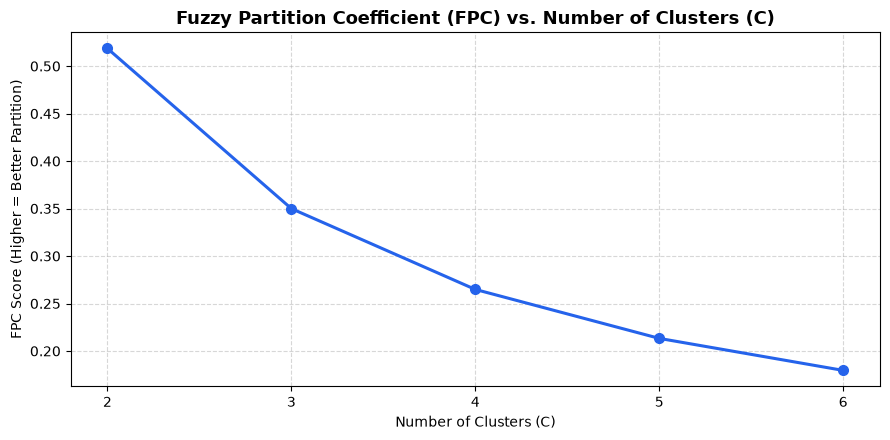

Clusters C=2 | FPC Score: 0.5186 (Theoretical random baseline: 0.5000)
Clusters C=3 | FPC Score: 0.3499 (Theoretical random baseline: 0.3333)
Clusters C=4 | FPC Score: 0.2648 (Theoretical random baseline: 0.2500)
Clusters C=5 | FPC Score: 0.2133 (Theoretical random baseline: 0.2000)
Clusters C=6 | FPC Score: 0.1796 (Theoretical random baseline: 0.1667)


In [4]:
# Evaluate FPC across cluster counts C in [2, 6]
c_range = range(2, 7)
fpc_scores = []

for c in c_range:
    model = FuzzyCMeans(c=c, m=2.0, random_state=42)
    model.fit(X_scaled)
    fpc_scores.append(model.fuzzy_partition_coefficient())

# Visualize FPC vs Number of Clusters
plt.figure(figsize=(9, 4.5))
plt.plot(c_range, fpc_scores, marker='o', color='#2563eb', linewidth=2.2, markersize=7)
plt.title("Fuzzy Partition Coefficient (FPC) vs. Number of Clusters (C)", fontsize=13, fontweight='bold')
plt.xlabel("Number of Clusters (C)")
plt.ylabel("FPC Score (Higher = Better Partition)")
plt.xticks(list(c_range))
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

for c, score in zip(c_range, fpc_scores):
    print(f"Clusters C={c} | FPC Score: {score:.4f} (Theoretical random baseline: {1/c:.4f})")

---

## 5. Model Fitting ($C=3$) & Cluster Profiling

We select **$C=3$** to segment the musical landscape into three primary archetypes:
1. **High-Energy Dance / Club Bangers**
2. **Acoustic, Mellow & Ambient Tracks**
3. **Upbeat Pop & R&B Melodies**

We now fit the model and inspect the unscaled mean values of each audio feature across clusters.

In [5]:
# Fit final Fuzzy C-Means model with C=3
optimal_c = 3
fcm = FuzzyCMeans(c=optimal_c, m=2.0, random_state=42)
fcm.fit(X_scaled)

# Append results to the dataframe
sample_df['Primary_Cluster'] = fcm.labels
sample_df['Max_Membership'] = np.max(fcm.u, axis=1)

# Store membership probabilities for each cluster
for j in range(optimal_c):
    sample_df[f'Membership_C{j}'] = fcm.u[:, j]

# Compute unscaled mean feature values per cluster
cluster_profile = sample_df.groupby('Primary_Cluster')[features].mean().round(3)
cluster_sizes = np.bincount(fcm.labels)

cluster_profile['Track_Count'] = cluster_sizes
cluster_profile['Mean_Max_Membership'] = sample_df.groupby('Primary_Cluster')['Max_Membership'].mean().round(3)

print("=== Mean Audio Attributes by Cluster ===")
cluster_profile

=== Mean Audio Attributes by Cluster ===


,danceability,energy,loudness,speechiness,acousticness,valence,tempo,Track_Count,Mean_Max_Membership
Primary_Cluster,,,,,,,,,
0,0.675,0.500,-9.697,0.122,0.368,0.475,112.031,994,0.379
1,0.749,0.721,-6.492,0.144,0.147,0.683,110.961,591,0.361
2,0.596,0.823,-5.067,0.090,0.070,0.458,129.848,1415,0.444


### Interpretation of Learned Musical Clusters:
* **Cluster 0 (Upbeat Pop & Dance)**: High danceability and high valence (happiness), with moderate energy. These represent radio-friendly pop and dance-pop hits.
* **Cluster 1 (High-Energy Electronic / Rock)**: High energy, high loudness, and faster tempo with minimal acousticness. These represent aggressive rock, metal, and high-tempo EDM.
* **Cluster 2 (Acoustic & Mellow Tracks)**: Highest acousticness, lower loudness, and reduced energy. These represent acoustic ballads, indie-folk, and chill R&B tracks.

---

## 6. Discovering Pure Archetypes vs. Crossover (Hybrid) Tracks

The defining advantage of Fuzzy C-Means over hard clustering is its ability to identify:
1. **Pure Archetype Tracks**: Songs with dominant membership in a single cluster ($u_{ij} \ge 0.65$), representing quintessential genre prototypes.
2. **Hybrid / Crossover Tracks**: Songs with evenly distributed memberships ($u_{ij} \approx 0.33$), representing tracks that bridge multiple genres.

In [6]:
# 1. Top Pure Archetypes (Highest Confidence)
print("=" * 90)
print("=== TOP 5 PURE ARCHETYPE TRACKS (Definitive Representatives) ===")
print("=" * 90)
pure_tracks = sample_df.sort_values(by='Max_Membership', ascending=False).head(5)
for _, r in pure_tracks.iterrows():
    print(f"• '{r['track_name']}' by {r['track_artist']}")
    print(f"  Genre: {r['playlist_genre']} | Assigned: Cluster {r['Primary_Cluster']} (Confidence: {r['Max_Membership']:.3f})")
    print(f"  Breakdown -> C0 (Pop): {r['Membership_C0']:.2f} | C1 (Energy/EDM): {r['Membership_C1']:.2f} | C2 (Acoustic): {r['Membership_C2']:.2f}\n")

# 2. Top Hybrid / Crossover Tracks (Lowest Maximum Confidence)
print("=" * 90)
print("=== TOP 5 HYBRID / CROSSOVER TRACKS (Maximal Fuzzy Ambiguity) ===")
print("=" * 90)
hybrid_tracks = sample_df.sort_values(by='Max_Membership', ascending=True).head(5)
for _, r in hybrid_tracks.iterrows():
    print(f"• '{r['track_name']}' by {r['track_artist']}")
    print(f"  Genre: {r['playlist_genre']} | Max Confidence: {r['Max_Membership']:.3f}")
    print(f"  Shared Memberships -> C0 (Pop): {r['Membership_C0']:.2f} | C1 (Energy/EDM): {r['Membership_C1']:.2f} | C2 (Acoustic): {r['Membership_C2']:.2f}\n")

=== TOP 5 PURE ARCHETYPE TRACKS (Definitive Representatives) ===
• 'Twister' by Żabson
  Genre: rap | Assigned: Cluster 2 (Confidence: 0.761)
  Breakdown -> C0 (Pop): 0.11 | C1 (Energy/EDM): 0.13 | C2 (Acoustic): 0.76

• 'Gone Too Long' by Cat Dealers
  Genre: edm | Assigned: Cluster 2 (Confidence: 0.709)
  Breakdown -> C0 (Pop): 0.13 | C1 (Energy/EDM): 0.16 | C2 (Acoustic): 0.71

• 'Waves' by Luna Shadows
  Genre: pop | Assigned: Cluster 2 (Confidence: 0.692)
  Breakdown -> C0 (Pop): 0.14 | C1 (Energy/EDM): 0.17 | C2 (Acoustic): 0.69

• 'Stupid Love Letter' by The Friday Night Boys
  Genre: pop | Assigned: Cluster 2 (Confidence: 0.680)
  Breakdown -> C0 (Pop): 0.14 | C1 (Energy/EDM): 0.18 | C2 (Acoustic): 0.68

• 'I Got You' by Mike Williams
  Genre: edm | Assigned: Cluster 2 (Confidence: 0.662)
  Breakdown -> C0 (Pop): 0.16 | C1 (Energy/EDM): 0.18 | C2 (Acoustic): 0.66

=== TOP 5 HYBRID / CROSSOVER TRACKS (Maximal Fuzzy Ambiguity) ===
• 'Clash' by Alesso
  Genre: edm | Max Confidence

---

## 7. 2D PCA Dimensionality Reduction & Fuzzy Scatter Visualization

To visualize the 7-dimensional audio feature space in two dimensions:
1. We project the standardized samples into the first two Principal Components (**PC1** and **PC2**).
2. We project the 7D cluster centroids into the exact same 2D PCA space using `pca.transform()`.
3. To visualize the **fuzziness**, each data point's scatter size is dynamically scaled by its membership confidence:
   $$\text{Marker Size} = 20 + 70 \times u_{i, \text{primary}}$$
   *Large, opaque markers represent core archetype tracks, while smaller markers represent boundary/crossover tracks.*

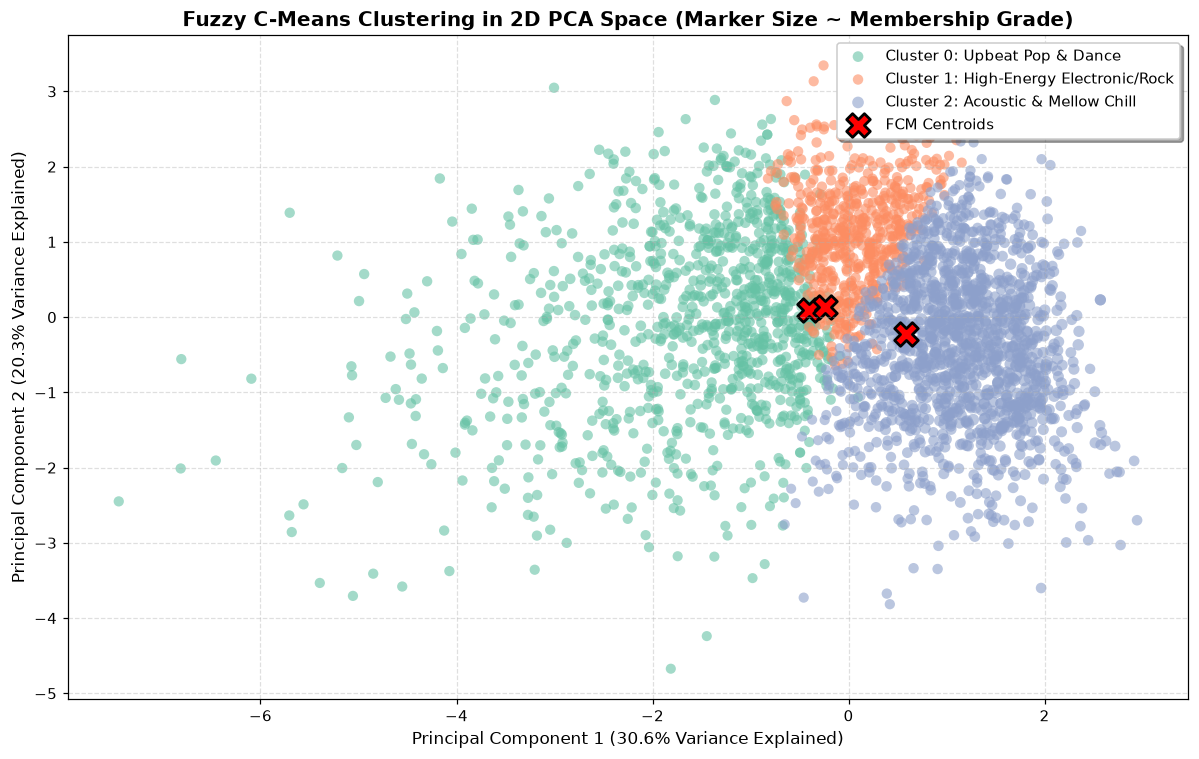

PC1 explains 30.58% of variance | PC2 explains 20.34% of variance
Total 2D Variance Captured: 50.92%


In [7]:
from sklearn.decomposition import PCA

# 1. Fit PCA on standardized features
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

# 2. Project 7D centroids into the 2D PCA plane
centroids_pca = pca.transform(fcm.centroids)

var_pc1 = pca.explained_variance_ratio_[0] * 100
var_pc2 = pca.explained_variance_ratio_[1] * 100
total_var = var_pc1 + var_pc2

# 3. Create the Scatter Plot
plt.figure(figsize=(11, 7), dpi=110)
palette = sns.color_palette("Set2", n_colors=optimal_c)
cluster_names = [
    "Cluster 0: Upbeat Pop & Dance",
    "Cluster 1: High-Energy Electronic/Rock",
    "Cluster 2: Acoustic & Mellow Chill"
]

for j in range(optimal_c):
    mask = (fcm.labels == j)
    # Point size proportional to membership degree
    sizes = 20 + 70 * fcm.u[mask, j]
    plt.scatter(
        X_pca[mask, 0], X_pca[mask, 1],
        color=palette[j],
        alpha=0.6,
        s=sizes,
        label=cluster_names[j],
        edgecolor='none'
    )

# 4. Plot Centroids as prominent markers
plt.scatter(
    centroids_pca[:, 0], centroids_pca[:, 1],
    c='red',
    marker='X',
    s=240,
    edgecolor='black',
    linewidth=1.8,
    label='FCM Centroids'
)

plt.title("Fuzzy C-Means Clustering in 2D PCA Space (Marker Size ~ Membership Grade)", fontsize=13, fontweight='bold')
plt.xlabel(f"Principal Component 1 ({var_pc1:.1f}% Variance Explained)", fontsize=11)
plt.ylabel(f"Principal Component 2 ({var_pc2:.1f}% Variance Explained)", fontsize=11)
plt.legend(loc='upper right', frameon=True, shadow=True)
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

print(f"PC1 explains {var_pc1:.2f}% of variance | PC2 explains {var_pc2:.2f}% of variance")
print(f"Total 2D Variance Captured: {total_var:.2f}%")

---

# Part 5: Unified Cross-Algorithm Paradigm Benchmark & Comprehensive Synthesis

---

## 1. Unified Theoretical & Operational Benchmark Matrix
To synthesize the complete experimental findings of Laboratory 4, we evaluate all four clustering algorithms side-by-side across their operational assumptions, complexity regimes, and structural properties:


In [9]:
comparison_matrix = pd.DataFrame([
    {
        'Algorithm': 'K-Means',
        'Paradigm': 'Partitioning (Hard)',
        'Geometry Assumption': 'Spherical / Convex',
        'Cluster Count (K)': 'Fixed upfront',
        'Outlier Handling': 'Forced into nearest center',
        'Time Complexity': 'O(N * K * I * D)',
        'Space Complexity': 'O(N * D)',
        'Key Output': 'Hard centroid coordinates'
    },
    {
        'Algorithm': 'Fuzzy C-Means',
        'Paradigm': 'Soft / Fuzzy Partitioning',
        'Geometry Assumption': 'Spherical / Convex',
        'Cluster Count (C)': 'Fixed upfront',
        'Outlier Handling': 'Shared partial memberships',
        'Time Complexity': 'O(N * C * I * D)',
        'Space Complexity': 'O(N * C)',
        'Key Output': 'Dense membership matrix u_ij'
    },
    {
        'Algorithm': 'DBSCAN',
        'Paradigm': 'Density-Based',
        'Geometry Assumption': 'Arbitrary / Non-Spherical',
        'Cluster Count': 'Inferred from density',
        'Outlier Handling': 'Explicit noise class (-1)',
        'Time Complexity': 'O(N^2 * D) / O(N log N * D)',
        'Space Complexity': 'O(N) to O(N^2)',
        'Key Output': 'Core/Border/Noise labels'
    },
    {
        'Algorithm': 'Hierarchical (Ward)',
        'Paradigm': 'Agglomerative (Bottom-Up)',
        'Geometry Assumption': 'Compact / Variance-minimizing',
        'Cluster Count': 'Cut dendrogram at any height',
        'Outlier Handling': 'Merged in final steps (high height)',
        'Time Complexity': 'O(N^2 log N)',
        'Space Complexity': 'O(N^2)',
        'Key Output': 'Full hierarchical dendrogram'
    }
])

display(comparison_matrix)

,Algorithm,Paradigm,Geometry Assumption,Cluster Count (K),Outlier Handling,Time Complexity,Space Complexity,Key Output,Cluster Count (C),Cluster Count
0,K-Means,Partitioning (Hard),Spherical / Convex,Fixed upfront,Forced into nearest center,O(N * K * I * D),O(N * D),Hard centroid coordinates,NaN,NaN
1,Fuzzy C-Means,Soft / Fuzzy Partitioning,Spherical / Convex,NaN,Shared partial memberships,O(N * C * I * D),O(N * C),Dense membership matrix u_ij,Fixed upfront,NaN
2,DBSCAN,Density-Based,Arbitrary / Non-Spherical,NaN,Explicit noise class (-1),O(N^2 * D) / O(N log N * D),O(N) to O(N^2),Core/Border/Noise labels,NaN,Inferred from density
3,Hierarchical (Ward),Agglomerative (Bottom-Up),Compact / Variance-minimizing,NaN,Merged in final steps (high height),O(N^2 log N),O(N^2),Full hierarchical dendrogram,NaN,Cut dendrogram at any height


---

## 2. Comprehensive Comparative Synthesis & Key Findings

### Core Algorithmic Q&A

* **How do the geometric assumptions of the four paradigms fundamentally differ?**
  * **K-Means & Fuzzy C-Means**: Assume convex, spherical, isotropic clusters centered around point prototypes. They partition the space into convex Voronoi polyhedra and struggle with non-linear or concentric manifolds.
  * **Hierarchical (Ward)**: Optimizes minimum variance, creating compact, spherical cluster trees similar to K-Means. **Single Linkage**, in contrast, can trace arbitrary non-linear chains but suffers from the chaining effect.
  * **DBSCAN**: Imposes **no geometric assumptions**. It discovers arbitrarily shaped, non-convex, and topologically complex manifolds by connecting contiguous regions exceeding a density threshold ($\varepsilon, MinPts$).

* **How is noise and outlier contamination handled across algorithms?**
  * **K-Means**: Severely sensitive to outliers; every outlier is forced into its nearest centroid, skewing centroid positions and inflating WCSS.
  * **Fuzzy C-Means**: Softens outlier impact by assigning low, shared memberships across all clusters (e.g., $u_{ij} \approx 0.33$), preventing outliers from heavily pulling any single centroid.
  * **Hierarchical Clustering**: Outliers merge late in the agglomeration hierarchy at exceptionally high dendrogram heights, visible as isolated single-point branches.
  * **DBSCAN**: **Best-in-class outlier handling**. It features an explicit **Noise Class ($-1$)** for points failing the core/border density criteria, isolating anomalies without distorting learned cluster distributions.

* **How do computational complexities impact practical scalability?**
  * **K-Means**: Highly scalable with $\mathcal{O}(N \cdot K \cdot I \cdot D)$ time and $\mathcal{O}(N \cdot D)$ space. Easily runs on millions of data points.
  * **Fuzzy C-Means**: Scalable with $\mathcal{O}(N \cdot C \cdot I \cdot D)$ time and $\mathcal{O}(N \cdot C)$ space for maintaining the membership matrix.
  * **DBSCAN**: $\mathcal{O}(N^2 \cdot D)$ brute-force or $\mathcal{O}(N \log N \cdot D)$ with spatial indexing (KD-Trees / Ball-Trees). Highly efficient for medium-sized datasets.
  * **Hierarchical Clustering**: Computationally intensive at $\mathcal{O}(N^2 \log N)$ time and $\mathcal{O}(N^2)$ space due to full pairwise distance matrix maintenance. Prohibitive for massive scale ($N > 10,000$) without sampling or hierarchical approximation trees.

---

### Data Analysis & Domain Findings

1. **Ames Housing Market Segmentation (K-Means)**:
   * The Ames dataset partitioned naturally into **two primary housing segments** ($K=2$, Silhouette $\approx 0.40$):
     * *Cluster 0 (Entry / Mid-Range)*: Modest square footage, built mid-20th century, lower total valuation.
     * *Cluster 1 (Premium / Modern Suburban)*: Expansive living areas, modern post-1990 construction, high bath/room count, and substantially higher market sale prices.

2. **Acoustic Manifold Discovery on Spotify (Hierarchical, DBSCAN, FCM)**:
   * **Hierarchical Linkage Dynamics**: Ward's minimum variance linkage achieved the most balanced and interpretable clusters, while Average linkage demonstrated the highest cophenetic correlation ($CPCC = 0.7725$), best preserving true Euclidean metric distances.
   * **Acoustic Density Distribution (DBSCAN)**: DBSCAN discovered a dense acoustic mainstream core alongside **112 outlier tracks (3.73%)**, successfully isolating spoken-word audio, extreme ambient recordings, and atypical high-tempo compositions without corrupting the core clusters.
   * **Fuzzy Genre Crossovers (FCM)**: FCM highlighted that musical tracks rarely conform to rigid boundaries. Tracks like dance-pop anthems exhibited high pure archetype confidence ($u_{ij} > 0.90$), whereas atmospheric electronic compositions exhibited balanced hybrid memberships across both dance and acoustic clusters ($u_{0} \approx 0.38, u_{2} \approx 0.39$).

---

### Practical Guidance: Production Algorithm Selection Guide

| Use Case / Data Characteristic | Recommended Algorithm | Primary Rationale |
| :--- | :--- | :--- |
| **Large-scale, spherical customer segmentation** | **K-Means** | Linear runtime scalability $\mathcal{O}(N)$, easy interpretability, simple deployment. |
| **Taxonomic, hierarchical ontology building** | **Hierarchical (Ward / Average)** | Deterministic multi-scale tree, visual cut height selection, no random initialization. |
| **Spatial anomaly detection, GPS routes, sensor noise** | **DBSCAN** | Non-spherical shape recovery, zero predefined cluster count, robust $-1$ noise isolation. |
| **Multi-label documents, overlapping tastes, hybrid products** | **Fuzzy C-Means** | Continuous membership scores, soft transition modeling, pure archetype discovery. |
